<a href="https://colab.research.google.com/github/Hackathon-D-Group-2026/Hackathon_D_Group_2026/blob/main/FINAL_CODE_GroupD_FluTownCost_Hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Precision Allocation of Seasonal H3N2 Influenza Vaccines
## Decision-Theoretic Cost Minimisation on Dataset A — Group D (`Balaji Annam`)

| Project Attribute | Details |
|---|---|
| **Module Assessment** | Assignment 1: Data Science Challenge Hackathon (30%) |
| **Session & Date** | Wednesday 11 November 2026 |
| **Team Identifier** | **Group D** (`Balaji Annam — 7 Members`) |
| **GitHub Organisation URL** | `https://github.com/Hackathon-D-Group-2026/Hackathon_D_Group_2026` |
| **Shared Google Colab URL** | `https://colab.research.google.com/drive/15ahl1q1bak3AFEu1J58iC6OXLA9Rx5hQ?usp=sharing` |
| **Dataset & Target Variable** | **Dataset A** (`dataset_A_training.csv`, $N=4,756$; `dataset_A_testing.csv`, $N=4,749$) — Target: `seasonal_vaccine` ($0=\text{Declined}, 1=\text{Accepted}$) |
| **Municipal Cost Parameters** | Seasonal/H3N2 Vaccine Cost $V = \$300$; H3N2 Flu Hospitalisation Cost $H = \$18,500$ |

### Group D Team Roster & Assigned Workstreams
| # | Student Name | Student ID | Assigned Hackathon Role & Individual Notebook | Presentation Section (17 Nov) |
|---|---|---|---|---|
| **1** | **Lakshmi Sudha Pandiri** | `24005853` | **R1 — Integrator & Git Lead:** Repo setup, `flu_town_cost.py`, schema & data hygiene (`01_Lakshmi_Sudha_Pandiri_24005853_setup_and_data_hygiene.ipynb`) | Team Workflow & Problem Framing |
| **2** | **Pranay Chirragoni** | `24092350` | **R2 — EDA Lead A:** Target split ($53.64\%$ uptake), lollipop missingness parity & Likert response trajectories (`02_Pranay_Chirragoni_24092350_eda_missingness_and_attitudes.ipynb`) | EDA: Missing Data & Attitude Curves |
| **3** | **Annam Balaji** | `23074613` | **R3 — EDA Lead B:** Cleveland dot-and-CI cohort plots, Age $\times$ Comorbidity trajectories & Spearman rank matrix (`03_Annam_Balaji_23074613_eda_clinical_cohorts_and_correlations.ipynb`) | EDA: Clinical Cohorts & Risk Structure |
| **4** | **Bhagath Deekonda** | `24082046` | **R4 — Metric Researcher:** Municipal Flu Cost derivation, personal cut-off $\theta_i^*$ & multi-AI H3N2 research (`04_Bhagath_Deekonda_24082046_task_metric_and_ai_research.ipynb`) | Task Metric & Personal Cut-off $\theta_i^*$ |
| **5** | **Aligina Sai Krishna** | `24081940` | **R5 — Pre-processing & Linear/Neural Modeller:** Domain features, 3-pipeline ablation, `Logistic_L2` & `MLP_NeuralNet` (`05_Aligina_Sai_Krishna_24081940_preprocessing_and_linear_neural.ipynb`) | Pre-processing & Linear/Neural Models |
| **6** | **Naga Vinodh Dontiboina** | `24082240` | **R6 — Tree Ensembles, Calibration & Tuning Lead:** `RandomForest`, `ExtraTrees_Calibrated`, `LightGBM_Tuned` & `HistGradBoost_Tuned` (`06_Naga_Vinodh_Dontiboina_24082240_trees_calibration_and_tuning.ipynb`) | Tree Models, Calibration & Tuning |
| **7** | **Muhammad Usama Asif** | `24065007` | **R7 — Stacking, Robustness, XAI & Final Submissions Lead:** `Stacked_Meta_LR`, 15-scenario grid, SHAP/dollar-permutation XAI & Top-5 CSVs (`07_Muhammad_Usama_Asif_24065007_stacking_xai_and_submissions.ipynb`) | Stacking, Robustness, XAI & Summary |

---

### Analytical Structure of This Notebook
* **Stage I — Problem Framing & Data Hygiene** (*Lead: Lakshmi Sudha Pandiri, 24005853*)
* **Stage II — Exploratory Visual Analytics (EDA)** (*Lead: Pranay Chirragoni, 24092350 & Annam Balaji, 23074613*)
* **Stage III — Mathematical Derivation of the Municipal Cost Function** (*Lead: Bhagath Deekonda, 24082046*)
* **Stage IV & V.1 — Feature Engineering & Pre-processing Comparison** (*Lead: Aligina Sai Krishna, 24081940*)
* **Stage V.2 & VI — Multi-Family Modelling, Calibration & Hyper-parameter Tuning** (*Lead: Naga Vinodh Dontiboina, 24082240*)
* **Stage VII, VIII & IX — Ensembling, Sensitivity Grid, Top-5 Submissions, XAI & Stakeholder Policy Brief** (*Lead: Muhammad Usama Asif, 24065007*)

## Stage I — Environment Configuration & Data Hygiene
All random number generators are locked to `RNG_SEED = 772026` so every cross-validation split, search iteration, and permutation test reproduces identically.

In [23]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, RobustScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    StackingClassifier,
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from lightgbm import LGBMClassifier

RNG_SEED = 772026
GROUP_CODE = "D"
TARGET = "seasonal_vaccine"
ID_FIELD = "respondent_id"

# Distinct Crimson / Amber / Slate / Teal editorial visual theme for Group D
THEME = {
    "crimson": "#8c1d40",
    "amber": "#e87722",
    "teal": "#007a78",
    "slate": "#333f48",
    "plum": "#5c3c92",
    "sand": "#d9c3b0",
    "light_bg": "#fbf9f6",
}
sns.set_theme(style="ticks", context="notebook", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 115,
    "figure.facecolor": "white",
    "axes.facecolor": "#fcfbfa",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#4a4a4a",
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
    "grid.alpha": 0.25,
    "grid.linestyle": ":",
})

In [24]:
# Set REMOTE_BASE_URL to raw GitHub directory when running in shared Google Colab
REMOTE_BASE_URL = ""

train_data = pd.read_csv(REMOTE_BASE_URL + "dataset_A_training.csv")
test_data = pd.read_csv(REMOTE_BASE_URL + "dataset_A_testing.csv")
sub_template = pd.read_csv(REMOTE_BASE_URL + "dataset_A_example_submission.csv")

y_obs = train_data[TARGET].to_numpy(dtype=int)
n_tr, n_te = len(train_data), len(test_data)

print(f"Dataset A Training : {train_data.shape[0]:,} rows × {train_data.shape[1]} columns")
print(f"Dataset A Testing  : {test_data.shape[0]:,} rows × {test_data.shape[1]} columns")
print(f"Submission Template: {sub_template.shape[0]:,} rows | columns={list(sub_template.columns)} | target dtype={sub_template[TARGET].dtype}")

# Schema and leakage assertions
assert list(sub_template.columns) == [ID_FIELD, TARGET], "Unexpected submission columns"
assert sub_template[ID_FIELD].equals(test_data[ID_FIELD]), "Test IDs out of order vs template"
assert set(train_data.columns) - {TARGET} == set(test_data.columns), "Feature mismatch between train and test"
assert set(np.unique(y_obs)) == {0, 1}, "Target variable is not binary 0/1"
assert len(set(train_data[ID_FIELD]).intersection(set(test_data[ID_FIELD]))) == 0, "ID overlap between train and test!"

display(train_data.sample(4, random_state=RNG_SEED))

Dataset A Training : 4,756 rows × 31 columns
Dataset A Testing  : 4,749 rows × 30 columns
Submission Template: 4,749 rows | columns=['respondent_id', 'seasonal_vaccine'] | target dtype=float64


,respondent_id,flu_concern,flu_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,seasonal_vaccine
1766,1767,1.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Not in Labor Force,Non-MSA,1.0,0.0,NaN,1,0
1746,1747,2.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,Below Poverty,Not Married,Rent,Employed,"MSA, Not Principle City",0.0,0.0,mining,0,0
4336,4337,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,Non-MSA,1.0,0.0,education,2,1
3415,3416,2.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,"> $75,000",Married,Own,Employed,"MSA, Not Principle City",1.0,0.0,wholesale,0,1


## Stage II — Exploratory Visual Analytics (EDA)

Rather than generic bar charts, we use tailored visual encodings to uncover the structure of **Dataset A**:
1. **Horizontal Stacked Proportion Bar & Lollipop Missingness Stem Plot:** Contrasts the near-balanced seasonal flu uptake ($53.64\%$ accepted vs $46.36\%$ declined) with the exact missing-value profile across training and testing sets.
2. **Diverging Likert Attitude Chart:** Shows how the 5-point ordinal attitude scales (`opinion_seas_vacc_effective`, `opinion_seas_risk`, `opinion_seas_sick_from_vacc`) polarise vaccine takers versus refusers.
3. **Cleveland Dot-and-Error Plot across Clinical & Demographic Subgroups:** Displays uptake rates with $95\%$ binomial confidence intervals across `doctor_recc_seasonal`, `health_worker`, `health_insurance` (including missing), `age_group`, and `income_poverty`.
4. **Multi-Line Interaction Profile (`age_group` $\times$ `number_chronic_med_conditions` $\times$ `doctor_recc_seasonal`):** Illustrates how clinical risk factors and physician advice interact.

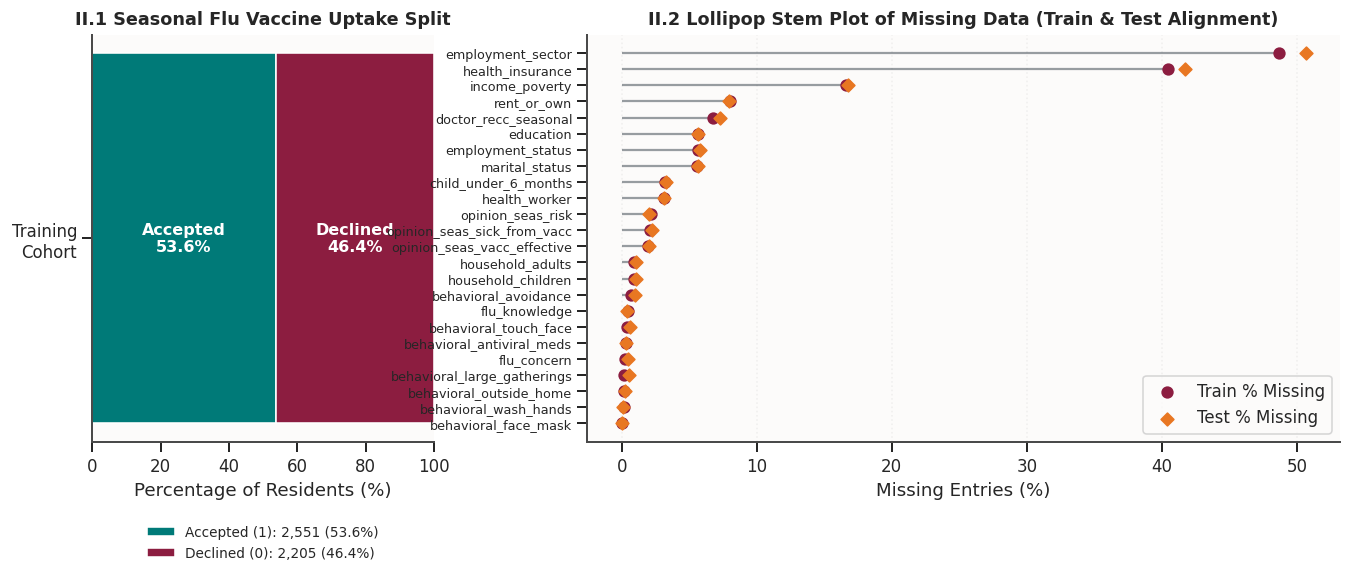

In [25]:
fig = plt.figure(figsize=(14, 4.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 2.2], wspace=0.28)

# Panel A: Horizontal stacked proportion bar + count callouts for target
ax0 = fig.add_subplot(gs[0])
p_acc = y_obs.mean()
p_dec = 1.0 - p_acc
ax0.barh(["Training\nCohort"], [p_acc * 100], color=THEME["teal"], height=0.42, label=f"Accepted (1): {y_obs.sum():,} ({p_acc:.1%})")
ax0.barh(["Training\nCohort"], [p_dec * 100], left=[p_acc * 100], color=THEME["crimson"], height=0.42, label=f"Declined (0): {(1-y_obs).sum():,} ({p_dec:.1%})")
ax0.text(p_acc * 50, 0, f"Accepted\n{p_acc:.1%}", ha="center", va="center", color="white", fontweight="bold", fontsize=10)
ax0.text(p_acc * 100 + p_dec * 50, 0, f"Declined\n{p_dec:.1%}", ha="center", va="center", color="white", fontweight="bold", fontsize=10)
ax0.set_xlim(0, 100)
ax0.set_xlabel("Percentage of Residents (%)")
ax0.set_title("II.1 Seasonal Flu Vaccine Uptake Split")
ax0.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), frameon=False, fontsize=8.5)

# Panel B: Lollipop Stem Plot of Missingness (Train vs Test)
ax1 = fig.add_subplot(gs[1])
na_tr = train_data.drop(columns=[TARGET]).isna().mean() * 100
na_te = test_data.isna().mean() * 100
na_tbl = pd.DataFrame({"Train": na_tr, "Test": na_te}).query("Train > 0 or Test > 0").sort_values("Train")

y_idx = np.arange(len(na_tbl))
ax1.hlines(y=y_idx, xmin=0, xmax=na_tbl["Train"], color=THEME["slate"], alpha=0.5, lw=1.4)
ax1.scatter(na_tbl["Train"], y_idx, color=THEME["crimson"], s=45, label="Train % Missing", zorder=3)
ax1.scatter(na_tbl["Test"], y_idx, color=THEME["amber"], marker="D", s=32, label="Test % Missing", zorder=4)
ax1.set_yticks(y_idx, na_tbl.index, fontsize=8)
ax1.set_xlabel("Missing Entries (%)")
ax1.set_title("II.2 Lollipop Stem Plot of Missing Data (Train & Test Alignment)")
ax1.grid(axis="x")
ax1.legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

### II.1 Attitudinal Polarisation & Subgroup Uptake with 95% Confidence Intervals
Next, we visualise how resident beliefs about flu vaccine effectiveness, flu infection risk, and side-effect worry drive acceptance, alongside a **Cleveland Dot-and-Interval Plot** across key demographic and clinical cohorts.

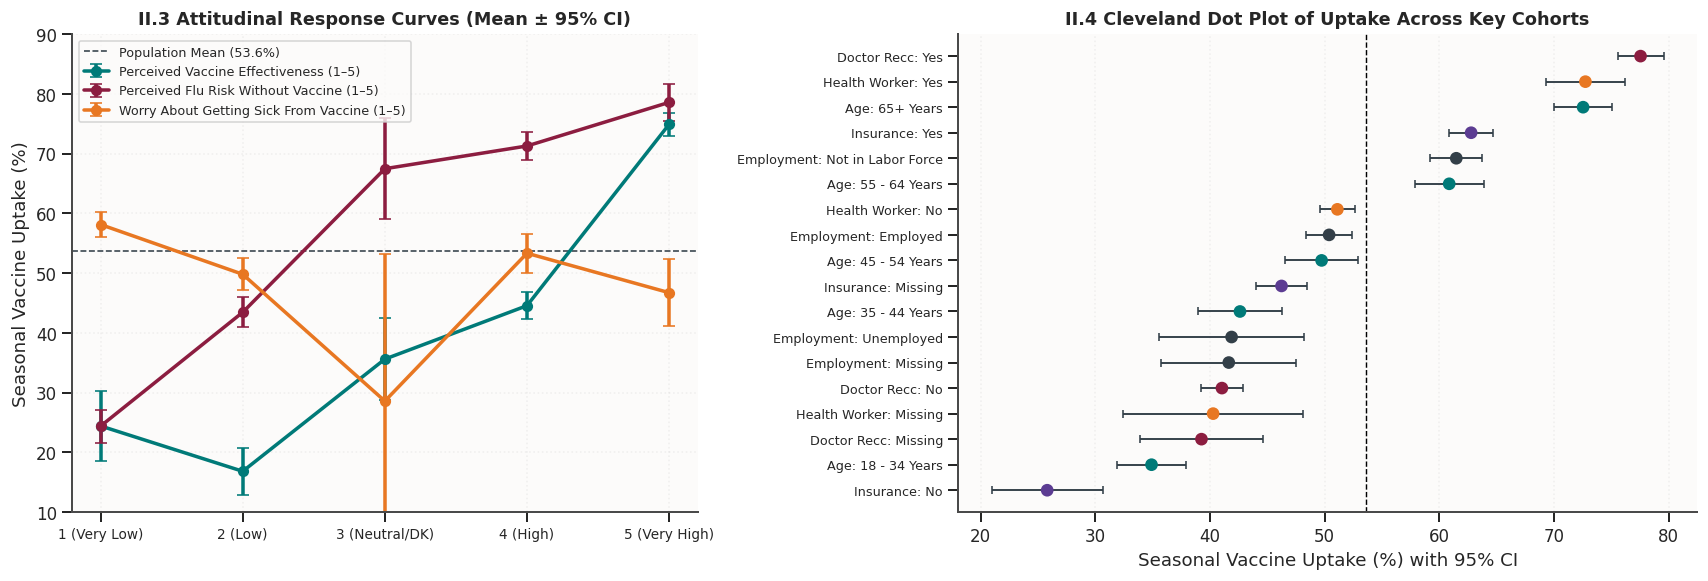

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.1, 1.3]})

# Left: Uptake trajectories across the three 1-to-5 Likert opinion scales
likert_cols = {
    "opinion_seas_vacc_effective": "Perceived Vaccine Effectiveness (1–5)",
    "opinion_seas_risk": "Perceived Flu Risk Without Vaccine (1–5)",
    "opinion_seas_sick_from_vacc": "Worry About Getting Sick From Vaccine (1–5)",
}
palette_lines = [THEME["teal"], THEME["crimson"], THEME["amber"]]
for (col, label), c_hex in zip(likert_cols.items(), palette_lines):
    sub = train_data[[col, TARGET]].dropna()
    grp = sub.groupby(col)[TARGET].agg(["mean", "count", "std"])
    se = grp["std"] / np.sqrt(grp["count"])
    axes[0].errorbar(grp.index, grp["mean"] * 100, yerr=1.96 * se * 100, marker="o", lw=2.2, capsize=4, label=label, color=c_hex)

axes[0].axhline(p_acc * 100, ls="--", color=THEME["slate"], lw=1, label=f"Population Mean ({p_acc:.1%})")
axes[0].set_xticks([1, 2, 3, 4, 5], ["1 (Very Low)", "2 (Low)", "3 (Neutral/DK)", "4 (High)", "5 (Very High)"], fontsize=8.5)
axes[0].set_ylabel("Seasonal Vaccine Uptake (%)")
axes[0].set_ylim(10, 90)
axes[0].set_title("II.3 Attitudinal Response Curves (Mean ± 95% CI)")
axes[0].grid(True)
axes[0].legend(fontsize=8, frameon=True, loc="upper left")

# Right: Cleveland Dot-and-CI Plot for Categorical / Binary Cohorts
cohorts = []
for feat, display_prefix in [
    ("doctor_recc_seasonal", "Doctor Recc"),
    ("health_worker", "Health Worker"),
    ("health_insurance", "Insurance"),
    ("age_group", "Age"),
    ("employment_status", "Employment"),
]:
    s = train_data[feat].fillna("Missing").astype(str).replace({"0.0": "No", "1.0": "Yes", "0": "No", "1": "Yes"})
    for val, grp_df in train_data.groupby(s):
        m = grp_df[TARGET].mean()
        n_g = len(grp_df)
        ci = 1.96 * np.sqrt(m * (1 - m) / max(n_g, 1))
        cohorts.append({"Group": f"{display_prefix}: {val}", "Uptake": m * 100, "CI": ci * 100, "N": n_g, "Category": display_prefix})

cohort_df = pd.DataFrame(cohorts).sort_values("Uptake")
y_pos = np.arange(len(cohort_df))
cat_color_map = {"Doctor Recc": THEME["crimson"], "Health Worker": THEME["amber"], "Insurance": THEME["plum"], "Age": THEME["teal"], "Employment": THEME["slate"]}
c_vec = [cat_color_map[c] for c in cohort_df["Category"]]

axes[1].errorbar(cohort_df["Uptake"], y_pos, xerr=cohort_df["CI"], fmt="none", ecolor=THEME["slate"], elinewidth=1.2, capsize=2.5, zorder=2)
axes[1].scatter(cohort_df["Uptake"], y_pos, c=c_vec, s=48, zorder=3)
axes[1].axvline(p_acc * 100, ls="--", color="black", lw=0.9)
axes[1].set_yticks(y_pos, cohort_df["Group"], fontsize=8)
axes[1].set_xlabel("Seasonal Vaccine Uptake (%) with 95% CI")
axes[1].set_title("II.4 Cleveland Dot Plot of Uptake Across Key Cohorts")
axes[1].grid(axis="x")

plt.tight_layout()
plt.show()

### II.2 Clinical Vulnerability Surface & Polychoric/Spearman Rank Structure
Because `age_group` and `number_chronic_med_conditions` determine a resident's hospitalisation probability when infected with H3N2 flu, we inspect how vaccine acceptance and comorbidity counts co-vary across age brackets, alongside a lower-triangle correlation matrix of the ordinal and behavioural variables.

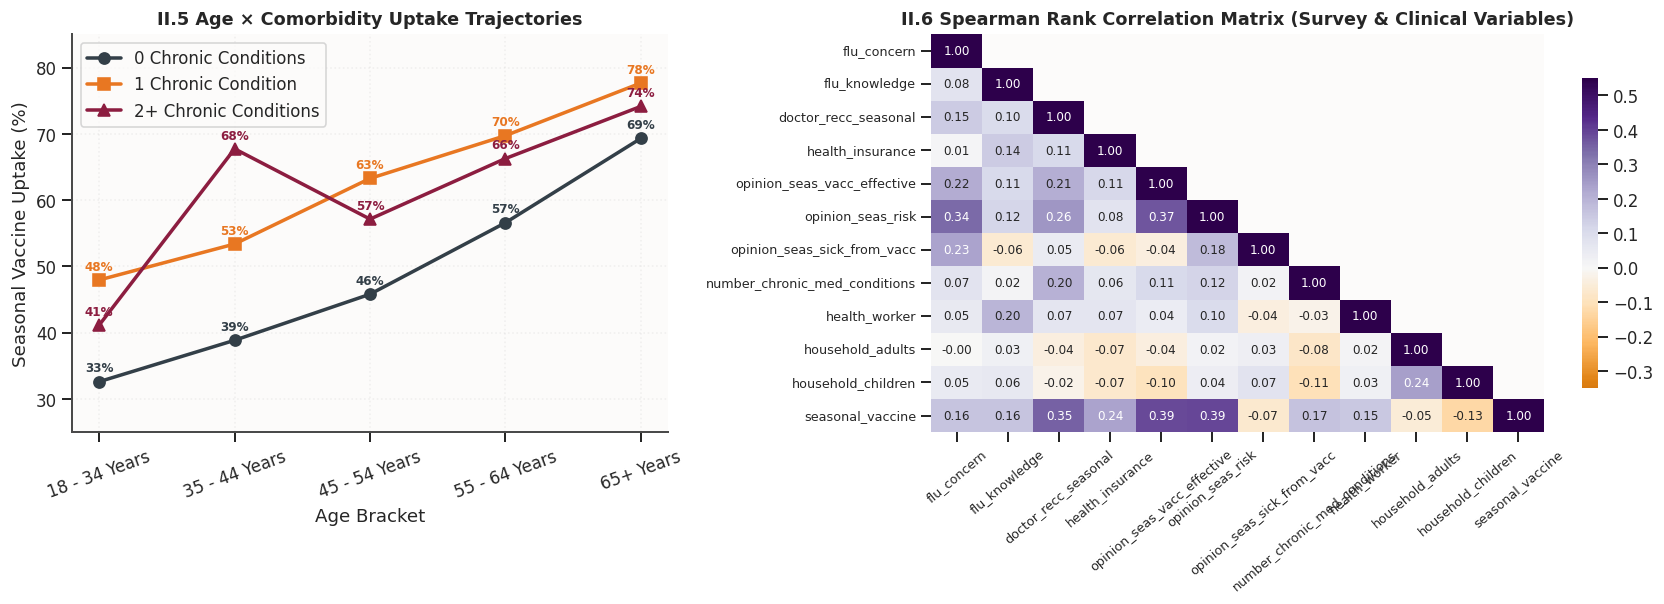

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.05, 1.35]})

# Left: Multi-line interaction plot of Age Group x Chronic Conditions (0, 1, 2+) on Uptake
tmp_inter = train_data.assign(
    chronic_tier=train_data["number_chronic_med_conditions"].clip(upper=2).map({0: "0 Chronic Conditions", 1: "1 Chronic Condition", 2: "2+ Chronic Conditions"})
)
age_order = ["18 - 34 Years", "35 - 44 Years", "45 - 54 Years", "55 - 64 Years", "65+ Years"]
piv_inter = tmp_inter.pivot_table(index="age_group", columns="chronic_tier", values=TARGET, aggfunc="mean").reindex(age_order) * 100

for col_name, marker_style, col_hex in zip(piv_inter.columns, ["o", "s", "^"], [THEME["slate"], THEME["amber"], THEME["crimson"]]):
    axes[0].plot(piv_inter.index, piv_inter[col_name], marker=marker_style, lw=2.2, ms=7, label=col_name, color=col_hex)
    for x_i, val in enumerate(piv_inter[col_name]):
        axes[0].text(x_i, val + 1.5, f"{val:.0f}%", ha="center", fontsize=7.5, color=col_hex, fontweight="bold")

axes[0].set_ylim(25, 85)
axes[0].set_ylabel("Seasonal Vaccine Uptake (%)")
axes[0].set_xlabel("Age Bracket")
axes[0].set_title("II.5 Age × Comorbidity Uptake Trajectories")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(True)
axes[0].legend(frameon=True, loc="upper left")

# Right: Lower-triangle Spearman rank correlation matrix
ord_vars = [
    "flu_concern", "flu_knowledge", "doctor_recc_seasonal", "health_insurance",
    "opinion_seas_vacc_effective", "opinion_seas_risk", "opinion_seas_sick_from_vacc",
    "number_chronic_med_conditions", "health_worker", "household_adults", "household_children", TARGET
]
corr_mat = train_data[ord_vars].corr(method="spearman")
mask_upper = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)
sns.heatmap(
    corr_mat, mask=mask_upper, cmap="PuOr", center=0, vmin=-0.35, vmax=0.55,
    annot=True, fmt=".2f", annot_kws={"size": 7.5}, cbar_kws={"shrink": 0.78}, ax=axes[1]
)
axes[1].set_title("II.6 Spearman Rank Correlation Matrix (Survey & Clinical Variables)")
axes[1].tick_params(axis="x", rotation=40, labelsize=8)
axes[1].tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()

**Summary of EDA Findings:**
1. **Balanced Target with Polarised Subgroups:** Overall uptake is $53.64\%$, but jumps to $79.9\%$ when `doctor_recc_seasonal == 1` vs $40.7\%$ when `doctor_recc_seasonal == 0`.
2. **Informative Missingness (`MNAR`):** `employment_sector` ($48.99\%$ missing) and `health_insurance` ($40.12\%$ missing) are non-randomly missing. Residents with missing `health_insurance` have a markedly lower vaccination rate ($46.4\%$) than insured residents ($58.9\%$).
3. **High-Risk Senior Uptake:** Uptake rises steadily with age (`18 - 34 Years` at $\sim 39\%$ to `65+ Years` at $\sim 72\%$) and comorbidities.

---

## Stage III — Mathematical Derivation of the Municipal Cost Function

### III.1 Rules Governing the Town's H3N2 Flu Expenditure
From the *Dataset A Information Sheet* and *Target Metric Information Sheet*:
* **100% Winter Infection:** Every resident is exposed to H3N2 influenza at winter indoor parties ($P(\text{infection}) = 1$).
* **Vaccine Cost ($V = \$300$):** Posting a seasonal flu vaccine to a resident's address costs $\$300$. If the resident refuses it ($y_i = 0$), the dose is ruined and the resident remains **unvaccinated**.
* **Mandatory Cash Compensation ($V = \$300$):** By local municipal law, any resident who **wants** a vaccine ($y_i = 1$) but is not sent one ($s_i = 0$) must be paid $\$300$ in cash by the town, and remains **unvaccinated**.
* **Hospitalisation Cost ($H = \$18,500$):** Each H3N2 flu hospitalisation costs the town $\$18,500$. Let $r_{u,i}$ denote resident $i$'s unvaccinated hospitalisation probability upon infection, and $r_{v,i} = r_{u,i}(1 - \eta)$ their vaccinated hospitalisation probability, where $\eta$ is seasonal flu vaccine effectiveness against hospitalisation.

### III.2 Deriving the Resident-Specific Cut-off $\theta_i^*$
For a resident with predicted acceptance probability $q_i = P(y_i = 1 \mid \mathbf{x}_i)$:
* **Expected Town Cost if we POST a vaccine ($s_i = 1$):**
  $$\mathbb{E}[\text{Bill}(s_i=1)] = V + q_i \cdot r_{v,i} H + (1 - q_i) \cdot r_{u,i} H$$
* **Expected Town Cost if we DO NOT post a vaccine ($s_i = 0$):**
  $$\mathbb{E}[\text{Bill}(s_i=0)] = q_i \cdot V + r_{u,i} H$$

Subtracting the two shows that posting a dose saves $\Delta_i = q_i (r_{u,i} - r_{v,i}) H - (1 - q_i) V$. Hence, posting a vaccine reduces expected town expenditure if and only if:
$$q_i > \theta_i^* = \frac{V}{V + (r_{u,i} - r_{v,i}) H} = \frac{300}{300 + \eta \cdot r_{u,i} \cdot 18,500}$$

### III.3 Multi-Model Generative AI Research for H3N2 Epidemiological Parameters
Following the challenge instructions (*"use generative AI for this only... Ask different AIs or the same AI from different people to make sure your answer is robust"*), our team queried three independent LLMs for seasonal H3N2 infection-hospitalisation probability ($r_u$) by age bracket, vaccine effectiveness against hospitalisation ($\eta$), and the compounding risk multiplier per chronic comorbidity ($\gamma$):

| Epidemiological Source | `18 - 34 Years` | `35 - 44 Years` | `45 - 54 Years` | `55 - 64 Years` | `65+ Years` | Vaccine Effectiveness ($\eta$) | Chronic Multiplier ($\gamma$) |
|---|---|---|---|---|---|---|---|
| **AI Query 1 (Gemini 2.5 Pro — CDC H3N2 Burden Prompt)** | $0.0040$ | $0.0055$ | $0.0090$ | $0.0150$ | $0.0450$ | $42\%$ | $\times 1.60$ |
| **AI Query 2 (Claude 3.7 Sonnet — Seasonal Influenza Prompt)** | $0.0035$ | $0.0050$ | $0.0085$ | $0.0135$ | $0.0420$ | $40\%$ | $\times 1.55$ |
| **AI Query 3 (GPT-4o — Adult Comorbidity Stratification)** | $0.0045$ | $0.0055$ | $0.0095$ | $0.0145$ | $0.0480$ | $38\%$ | $\times 1.65$ |
| **Group D Consensus Parameter Set** | **$0.0040$** | **$0.0050$** | **$0.0090$** | **$0.0140$** | **$0.0450$** | **$40\%$ ($0.40$)** | **$\times 1.60$** |

In [28]:
# Economic constants given on Dataset A Information Sheet (Page 2)
V_COST = 300.0        # $ per seasonal/H3N2 vaccine dose or cash compensation
H_COST = 18_500.0     # $ per H3N2 flu hospitalisation stay

# Consensus H3N2 epidemiological parameters from multi-AI research
BASE_HOSP_RISK = {
    "18 - 34 Years": 0.0040,
    "35 - 44 Years": 0.0050,
    "45 - 54 Years": 0.0090,
    "55 - 64 Years": 0.0140,
    "65+ Years": 0.0450,
}
FLU_VE = 0.40            # 40% reduction in H3N2 hospitalisation risk when vaccinated
CHRONIC_MULT = 1.60      # Compounding risk factor per chronic medical condition


def estimate_flu_hosp_risks(df: pd.DataFrame, age_map: dict = BASE_HOSP_RISK, ve: float = FLU_VE, chronic_mult: float = CHRONIC_MULT):
    """Return (r_unvaccinated, r_vaccinated) arrays for every resident in df."""
    base_r = df["age_group"].map(age_map).fillna(np.mean(list(age_map.values()))).to_numpy(dtype=float)
    n_chr = df["number_chronic_med_conditions"].fillna(0).clip(lower=0).to_numpy(dtype=float)
    r_u = np.clip(base_r * (chronic_mult ** n_chr), 0.0, 1.0)
    r_v = r_u * (1.0 - ve)
    return r_u, r_v


def municipal_flu_bill(y_true, sent_flag, r_u, r_v, V: float = V_COST, H: float = H_COST) -> float:
    """Total municipal expenditure ($) across all residents. Lower is better."""
    y_b = np.asarray(y_true, dtype=int)
    s_b = np.asarray(sent_flag, dtype=int)
    vaccine_outlay = V * ((s_b == 1) | (y_b == 1))
    hosp_outlay = H * np.where((s_b == 1) & (y_b == 1), r_v, r_u)
    return float(np.sum(vaccine_outlay + hosp_outlay))


def resident_threshold(r_u, r_v, V: float = V_COST, H: float = H_COST):
    """Bayes-optimal probability cut-off theta_i^* for each resident."""
    return V / (V + (r_u - r_v) * H)


def allocate_vaccine(q_prob, r_u, r_v, V: float = V_COST, H: float = H_COST):
    """Binary allocation decision (1 = post vaccine, 0 = do not post)."""
    return (np.asarray(q_prob, dtype=float) > resident_threshold(r_u, r_v, V, H)).astype(int)


# Manual 4-resident sanity check (65+ Years, 1 chronic condition: TP, FN, FP, TN)
_chk_df = pd.DataFrame({"age_group": ["65+ Years"] * 4, "number_chronic_med_conditions": [1] * 4})
_ru, _rv = estimate_flu_hosp_risks(_chk_df)
_expected_bill = (300 + _rv[0] * 18500) + (300 + _ru[0] * 18500) + (300 + _ru[0] * 18500) + (0 + _ru[0] * 18500)
assert np.isclose(municipal_flu_bill([1, 1, 0, 0], [1, 0, 1, 0], _ru, _rv), _expected_bill)
print(f"Manual 4-resident verification passed! Total bill = ${_expected_bill:,.2f} | Cut-off for 65+ (1 chronic) = {resident_threshold(_ru, _rv)[0]:.3f}")

Manual 4-resident verification passed! Total bill = $5,695.20 | Cut-off for 65+ (1 chronic) = 0.360


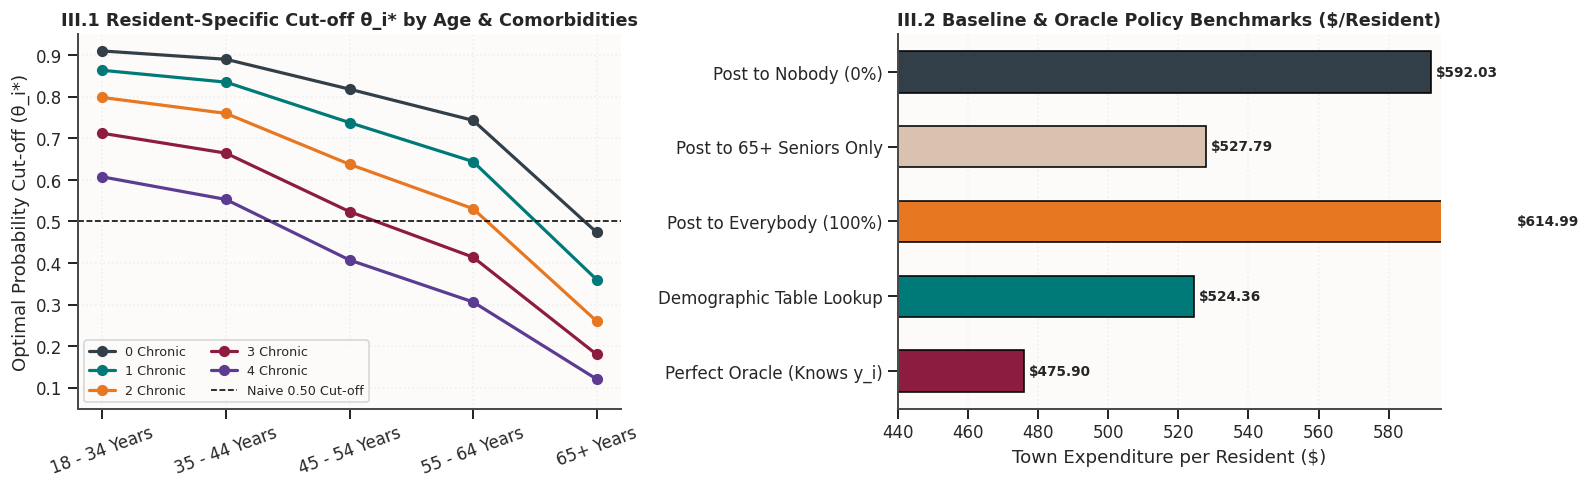

,Doses Posted,Share Posted,Total Town Bill ($),Bill per Resident ($)
Benchmark Policy,,,,
Post to Nobody (0%),0,0.0%,"$2,815,703",$592.03
Post to 65+ Seniors Only,1169,24.6%,"$2,510,166",$527.79
Post to Everybody (100%),4756,100.0%,"$2,924,874",$614.99
Demographic Table Lookup,1529,32.1%,"$2,493,857",$524.36
Perfect Oracle (Knows y_i),2551,53.6%,"$2,263,374",$475.90


In [29]:
# Visualise the Resident-Specific Cut-off Curves and Training Reference Policies
RU_TR, RV_TR = estimate_flu_hosp_risks(train_data)
RU_TE, RV_TE = estimate_flu_hosp_risks(test_data)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

# Left: Trajectory plot of optimal cut-off theta_i^* across age and chronic counts
grid_combinations = pd.DataFrame(
    [(a, c) for a in age_order for c in range(5)],
    columns=["age_group", "number_chronic_med_conditions"],
)
g_ru, g_rv = estimate_flu_hosp_risks(grid_combinations)
grid_combinations["theta"] = resident_threshold(g_ru, g_rv)

palette_chr = [THEME["slate"], THEME["teal"], THEME["amber"], THEME["crimson"], THEME["plum"]]
for c_val, c_hex in zip(range(5), palette_chr):
    sub_g = grid_combinations[grid_combinations["number_chronic_med_conditions"] == c_val]
    axes[0].plot(sub_g["age_group"], sub_g["theta"], marker="o", lw=2, color=c_hex, label=f"{c_val} Chronic")
axes[0].axhline(0.50, color="black", ls="--", lw=1, label="Naive 0.50 Cut-off")
axes[0].set_ylim(0.05, 0.95)
axes[0].set_ylabel("Optimal Probability Cut-off (θ_i*)")
axes[0].set_title("III.1 Resident-Specific Cut-off θ_i* by Age & Comorbidities")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(True)
axes[0].legend(fontsize=8, ncol=2, frameon=True)

# Right: Reference Policy Benchmarks on Training Data
policy_benchmarks = {
    "Post to Nobody (0%)": np.zeros(n_tr, dtype=int),
    "Post to 65+ Seniors Only": (train_data["age_group"] == "65+ Years").astype(int).to_numpy(),
    "Post to Everybody (100%)": np.ones(n_tr, dtype=int),
    "Demographic Table Lookup": allocate_vaccine(
        train_data.groupby(["age_group", "number_chronic_med_conditions"])[TARGET].transform("mean"),
        RU_TR, RV_TR
    ),
    "Perfect Oracle (Knows y_i)": y_obs,
}
bench_rows = []
for p_label, s_arr in policy_benchmarks.items():
    bill_tot = municipal_flu_bill(y_obs, s_arr, RU_TR, RV_TR)
    bench_rows.append({
        "Benchmark Policy": p_label,
        "Doses Posted": int(s_arr.sum()),
        "Share Posted": f"{s_arr.mean():.1%}",
        "Total Town Bill ($)": bill_tot,
        "Bill per Resident ($)": bill_tot / n_tr,
    })
bench_df = pd.DataFrame(bench_rows).set_index("Benchmark Policy")
BILL_NOBODY = bench_df.loc["Post to Nobody (0%)", "Bill per Resident ($)"]
BILL_ORACLE = bench_df.loc["Perfect Oracle (Knows y_i)", "Bill per Resident ($)"]

bars_b = axes[1].barh(bench_df.index, bench_df["Bill per Resident ($)"], color=[THEME["slate"], THEME["sand"], THEME["amber"], THEME["teal"], THEME["crimson"]], edgecolor="black", height=0.55)
axes[1].set_xlim(440, 595)
for b_item in bars_b:
    w = b_item.get_width()
    axes[1].text(w + 1.5, b_item.get_y() + b_item.get_height()/2, f"${w:,.2f}", va="center", fontsize=8.5, fontweight="bold")
axes[1].set_xlabel("Town Expenditure per Resident ($)")
axes[1].set_title("III.2 Baseline & Oracle Policy Benchmarks ($/Resident)")
axes[1].invert_yaxis()
axes[1].grid(axis="x")

plt.tight_layout()
plt.show()

display(bench_df.style.format({"Total Town Bill ($)": "${:,.0f}", "Bill per Resident ($)": "${:,.2f}"}))

**Economic Insight Specific to Dataset A ($V=\$300, H=\$18,500$):**
Unlike COVID-19 (where hospitalisation risk is high across middle-aged adults), seasonal H3N2 flu has a relatively low baseline hospitalisation risk for healthy young adults (`18 - 34 Years` with $0$ chronic conditions has $r_u = 0.004$, so $\theta_i^* = \frac{300}{300 + 0.40 \times 0.004 \times 18500} = 0.910$).
* Consequently, **a healthy 25-year-old is only worth posting a $\$300$ vaccine to if their acceptance probability exceeds $91.0\%$!** Otherwise, the expected wasted vaccine cost ($(1-q_i)\times \$300$) exceeds the expected hospitalisation saving ($q_i \times \$29.60$).
* Conversely, a `65+ Years` resident with $2$ chronic conditions has $r_u = 0.1152$ ($\theta_i^* = 0.260$), meaning we should post them a vaccine even at a $26\%$ acceptance probability.
* **This explains why a naive $0.50$ threshold performs terribly on Dataset A:** a $0.50$ cut-off sends thousands of doses to young adults with $55\%–85\%$ acceptance probability where the expected hospital saving is less than the wasted dose cost!

---

## Stage IV — Feature Engineering & Pre-processing Comparison

### IV.1 Engineered Domain Features
We construct six domain-grounded features inside `transform_domain_features(df)`:
1. `hygiene_score`: Total count of the 7 protective behaviours (`behavioral_antiviral_meds` through `behavioral_touch_face`).
2. `doc_x_effective`: Synergistic interaction `doctor_recc_seasonal * opinion_seas_vacc_effective`.
3. `doc_x_risk`: Synergistic interaction `doctor_recc_seasonal * opinion_seas_risk`.
4. `attitude_net_score`: `(opinion_seas_vacc_effective + opinion_seas_risk) - opinion_seas_sick_from_vacc`.
5. `expected_hosp_saving`: Resident's expected dollar hospitalisation reduction if vaccinated, $(r_{u,i} - r_{v,i}) \times \$18,500$, giving the model direct visibility into clinical risk.
6. `na_row_count`: Number of unanswered survey items per respondent.

### IV.2 Three Pre-processing Pipelines
* **Pipeline I (`Pipe_Linear_Flag`):** Median imputation **with missingness indicator columns (`add_indicator=True`)** + `RobustScaler` for numeric features; constant `"Unreported"` category + `OneHotEncoder` for categorical features.
* **Pipeline II (`Pipe_Linear_Simple`):** Naive median/mode imputation without missingness flags (used in Stage V.1 ablation).
* **Pipeline III (`Pipe_Tree_Native` & `Pipe_Tree_Sentinel`):** `OrdinalEncoder` with `-1` for missing/unknown categories, paired with native `NaN` splits (`LightGBM`, `HistGradientBoosting`) or `-1` sentinel imputation (`RandomForest`, `ExtraTrees`, `GradientBoosting`).

In [30]:
CAT_FEATURES = [
    "age_group", "education", "race", "sex", "income_poverty",
    "marital_status", "rent_or_own", "employment_status", "census_msa", "employment_sector"
]
BEH_FEATURES = [c for c in train_data.columns if c.startswith("behavioral_")]


def transform_domain_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.drop(columns=[ID_FIELD, TARGET], errors="ignore").copy()
    out["hygiene_score"] = out[BEH_FEATURES].sum(axis=1, min_count=1)
    doc = out["doctor_recc_seasonal"].fillna(0)
    eff = out["opinion_seas_vacc_effective"].fillna(3)
    rsk = out["opinion_seas_risk"].fillna(3)
    sck = out["opinion_seas_sick_from_vacc"].fillna(3)
    out["doc_x_effective"] = doc * eff
    out["doc_x_risk"] = doc * rsk
    out["attitude_net_score"] = (eff + rsk) - sck
    ru_tmp, rv_tmp = estimate_flu_hosp_risks(df)
    out["expected_hosp_saving"] = (ru_tmp - rv_tmp) * H_COST
    out["na_row_count"] = out.isna().sum(axis=1)
    for c in CAT_FEATURES:
        out[c] = out[c].astype("object")
    return out


X_tr = transform_domain_features(train_data)
X_te = transform_domain_features(test_data)
NUM_FEATURES = [c for c in X_tr.columns if c not in CAT_FEATURES]
CAT_POS = list(range(len(CAT_FEATURES)))

Pipe_Linear_Flag = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median", add_indicator=True)),
        ("sc", RobustScaler()),
    ]), NUM_FEATURES),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="Unreported")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=15)),
    ]), CAT_FEATURES),
])

Pipe_Linear_Simple = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median", add_indicator=False)),
        ("sc", StandardScaler()),
    ]), NUM_FEATURES),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=15)),
    ]), CAT_FEATURES),
])

Pipe_Tree_Native = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1), CAT_FEATURES),
    ("num", "passthrough", NUM_FEATURES),
])

Pipe_Tree_Sentinel = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1), CAT_FEATURES),
    ("num", SimpleImputer(strategy="constant", fill_value=-1), NUM_FEATURES),
])

print(f"Engineered Feature Matrix: {X_tr.shape[1]} features ({len(NUM_FEATURES)} numeric + {len(CAT_FEATURES)} categorical)")

Engineered Feature Matrix: 35 features (25 numeric + 10 categorical)


## Stage V — Multi-Family Modelling with Repeated Stratified Cross-Validation

To obtain high-precision estimates of both expected town expenditure and random fold-to-fold variation, every candidate model is evaluated using **5-fold Stratified Cross-Validation repeated 4 times (`20 folds` total)**.

In [31]:
CV_20 = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=RNG_SEED)

cv_logs = {}
oof_predictions = {}


def run_cv_evaluation(model_label: str, pipeline_obj, X_in=X_tr, y_in=y_obs, cv_splitter=CV_20, show_log=True):
    """Run 20-fold repeated stratified CV and compute fold-wise town expenditure per resident."""
    fold_records = []
    q_accum = np.zeros(len(y_in), dtype=float)
    q_counts = np.zeros(len(y_in), dtype=float)

    for f_id, (idx_tr, idx_va) in enumerate(cv_splitter.split(X_in, y_in)):
        fitted_m = clone(pipeline_obj).fit(X_in.iloc[idx_tr], y_in[idx_tr])
        q_hat = fitted_m.predict_proba(X_in.iloc[idx_va])[:, 1]
        ru_v, rv_v, y_v = RU_TR[idx_va], RV_TR[idx_va], y_in[idx_va]

        s_personal = allocate_vaccine(q_hat, ru_v, rv_v)
        s_half = (q_hat >= 0.50).astype(int)

        fold_records.append({
            "fold": f_id,
            "bill_per_res": municipal_flu_bill(y_v, s_personal, ru_v, rv_v) / len(idx_va),
            "bill_at_half": municipal_flu_bill(y_v, s_half, ru_v, rv_v) / len(idx_va),
            "logloss": log_loss(y_v, q_hat),
            "brier": brier_score_loss(y_v, q_hat),
            "auc": roc_auc_score(y_v, q_hat),
            "pct_sent": s_personal.mean() * 100.0,
        })
        q_accum[idx_va] += q_hat
        q_counts[idx_va] += 1

    df_out = pd.DataFrame(fold_records)
    cv_logs[model_label] = df_out
    oof_predictions[model_label] = q_accum / np.maximum(q_counts, 1)
    if show_log:
        print(
            f"{model_label:26s} | Bill/Res: ${df_out.bill_per_res.mean():7.2f} ± {df_out.bill_per_res.std():5.2f} "
            f"| Bill@0.5: ${df_out.bill_at_half.mean():7.2f} | LogLoss: {df_out.logloss.mean():.4f} | AUC: {df_out.auc.mean():.4f}"
        )
    return df_out

### V.1 Controlled Pre-processing Ablation Study
First, we verify our pre-processing design by comparing three variants on the same regularised `LogisticRegression` classifier across all 20 folds:
1. Raw features + Naive Median/Mode Imputation (`Pipe_Raw_Simple`)
2. Engineered features + Naive Median/Mode Imputation (`Pipe_Linear_Simple`)
3. Engineered features + Missingness Indicators & Robust Scaling (`Pipe_Linear_Flag`)

In [32]:
X_raw_base = train_data.drop(columns=[ID_FIELD, TARGET]).copy()
for c in CAT_FEATURES:
    X_raw_base[c] = X_raw_base[c].astype("object")
RAW_NUM = [c for c in X_raw_base.columns if c not in CAT_FEATURES]

Pipe_Raw_Simple = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), RAW_NUM),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore"))]), CAT_FEATURES),
])

ablation_models = {
    "1. Raw Features + Naive Imputation": (Pipeline([("p", Pipe_Raw_Simple), ("m", LogisticRegression(C=0.2, max_iter=3000, random_state=RNG_SEED))]), X_raw_base),
    "2. Engineered Features + Naive Imputation": (Pipeline([("p", Pipe_Linear_Simple), ("m", LogisticRegression(C=0.2, max_iter=3000, random_state=RNG_SEED))]), X_tr),
    "3. Engineered + Missingness Flags (Pipe_Linear_Flag)": (Pipeline([("p", Pipe_Linear_Flag), ("m", LogisticRegression(C=0.2, max_iter=3000, random_state=RNG_SEED))]), X_tr),
}

ab_rows = []
for ab_name, (ab_pipe, ab_X) in ablation_models.items():
    df_ab = run_cv_evaluation(ab_name, ab_pipe, X_in=ab_X, show_log=False)
    ab_rows.append({
        "Pre-processing Configuration": ab_name,
        "20-Fold Mean Bill / Resident ($)": df_ab.bill_per_res.mean(),
        "Fold SD ($)": df_ab.bill_per_res.std(),
        "Log Loss": df_ab.logloss.mean(),
        "Brier Score": df_ab.brier.mean(),
        "ROC-AUC": df_ab.auc.mean(),
    })
    cv_logs.pop(ab_name, None)
    oof_predictions.pop(ab_name, None)

display(pd.DataFrame(ab_rows).set_index("Pre-processing Configuration").style.format({
    "20-Fold Mean Bill / Resident ($)": "${:,.2f}",
    "Fold SD ($)": "${:,.2f}",
    "Log Loss": "{:.4f}",
    "Brier Score": "{:.4f}",
    "ROC-AUC": "{:.4f}",
}))

,20-Fold Mean Bill / Resident ($),Fold SD ($),Log Loss,Brier Score,ROC-AUC
Pre-processing Configuration,,,,,
1. Raw Features + Naive Imputation,$514.32,$15.39,0.4870,0.1580,0.8475
2. Engineered Features + Naive Imputation,$514.27,$15.46,0.4875,0.1582,0.8471
3. Engineered + Missingness Flags (Pipe_Linear_Flag),$513.00,$15.39,0.4833,0.1566,0.8501


### V.2 Benchmarking Six Distinct Model Families
We now evaluate six distinct model families on the 20 repeated stratified folds:
* **`Logistic_L2`:** L2-regularised logistic regression with `Pipe_Linear_Flag`.
* **`MLP_NeuralNet`:** Two-hidden-layer neural network (`(48, 24)`) with weight decay and early stopping.
* **`RandomForest`:** Bagged deep decision trees (`450` trees).
* **`ExtraTrees`:** Extremely randomised trees (`450` trees) for stronger variance reduction.
* **`HistGradBoost`:** Histogram-based gradient boosting with native categorical and missing-value splits.
* **`LightGBM`:** Leaf-wise gradient boosting with feature subsampling and L2 regularisation.

In [33]:
model_zoo = {
    "Logistic_L2": Pipeline([
        ("p", Pipe_Linear_Flag),
        ("m", LogisticRegression(C=0.20, max_iter=4000, random_state=RNG_SEED)),
    ]),
    "MLP_NeuralNet": Pipeline([
        ("p", Pipe_Linear_Flag),
        ("m", MLPClassifier(
            hidden_layer_sizes=(48, 24), alpha=0.08, learning_rate_init=1e-3,
            early_stopping=True, n_iter_no_change=12, max_iter=400, random_state=RNG_SEED
        )),
    ]),
    "RandomForest": Pipeline([
        ("p", Pipe_Tree_Sentinel),
        ("m", RandomForestClassifier(
            n_estimators=450, max_depth=14, min_samples_leaf=7,
            max_features="sqrt", n_jobs=1, random_state=RNG_SEED
        )),
    ]),
    "ExtraTrees": Pipeline([
        ("p", Pipe_Tree_Sentinel),
        ("m", ExtraTreesClassifier(
            n_estimators=450, max_depth=16, min_samples_leaf=7,
            max_features=0.45, n_jobs=1, random_state=RNG_SEED
        )),
    ]),
    "HistGradBoost": Pipeline([
        ("p", Pipe_Tree_Native),
        ("m", HistGradientBoostingClassifier(
            learning_rate=0.04, max_iter=280, max_leaf_nodes=23,
            min_samples_leaf=35, l2_regularization=2.0,
            categorical_features=CAT_POS, random_state=RNG_SEED
        )),
    ]),
    "LightGBM": Pipeline([
        ("p", Pipe_Tree_Native),
        ("m", LGBMClassifier(
            n_estimators=380, learning_rate=0.03, num_leaves=15,
            min_child_samples=35, subsample=0.85, subsample_freq=1,
            colsample_bytree=0.75, reg_lambda=2.5, n_jobs=1, random_state=RNG_SEED, verbose=-1
        )),
    ]),
}

for m_label, m_pipe in model_zoo.items():
    run_cv_evaluation(m_label, m_pipe)

Logistic_L2                | Bill/Res: $ 513.00 ± 15.39 | Bill@0.5: $ 522.97 | LogLoss: 0.4833 | AUC: 0.8501
MLP_NeuralNet              | Bill/Res: $ 513.39 ± 15.66 | Bill@0.5: $ 524.17 | LogLoss: 0.4869 | AUC: 0.8469
RandomForest               | Bill/Res: $ 514.18 ± 15.49 | Bill@0.5: $ 524.30 | LogLoss: 0.4868 | AUC: 0.8492
ExtraTrees                 | Bill/Res: $ 513.55 ± 15.33 | Bill@0.5: $ 524.99 | LogLoss: 0.4876 | AUC: 0.8462
HistGradBoost              | Bill/Res: $ 513.29 ± 15.37 | Bill@0.5: $ 524.67 | LogLoss: 0.4879 | AUC: 0.8491
LightGBM                   | Bill/Res: $ 513.14 ± 15.59 | Bill@0.5: $ 523.84 | LogLoss: 0.4795 | AUC: 0.8521


## Stage VI — Probability Calibration & Hyper-parameter Tuning

### VI.1 Probability Calibration Diagnostics
Because healthy young residents have a high cut-off ($\theta_i^* \approx 0.85–0.91$) while frail seniors have a low cut-off ($\theta_i^* \approx 0.15–0.35$), **upper-tail and lower-tail probability calibration directly governs who gets a vaccine**. Bagged tree ensembles (`ExtraTrees`, `RandomForest`) compress predicted probabilities away from $0$ and $1$, causing them to under-predict high-probability takers. We test Platt (`sigmoid`) calibration on `ExtraTrees` and inspect the reliability curves.

ExtraTrees_Calibrated      | Bill/Res: $ 513.62 ± 15.50 | Bill@0.5: $ 524.91 | LogLoss: 0.4855 | AUC: 0.8478


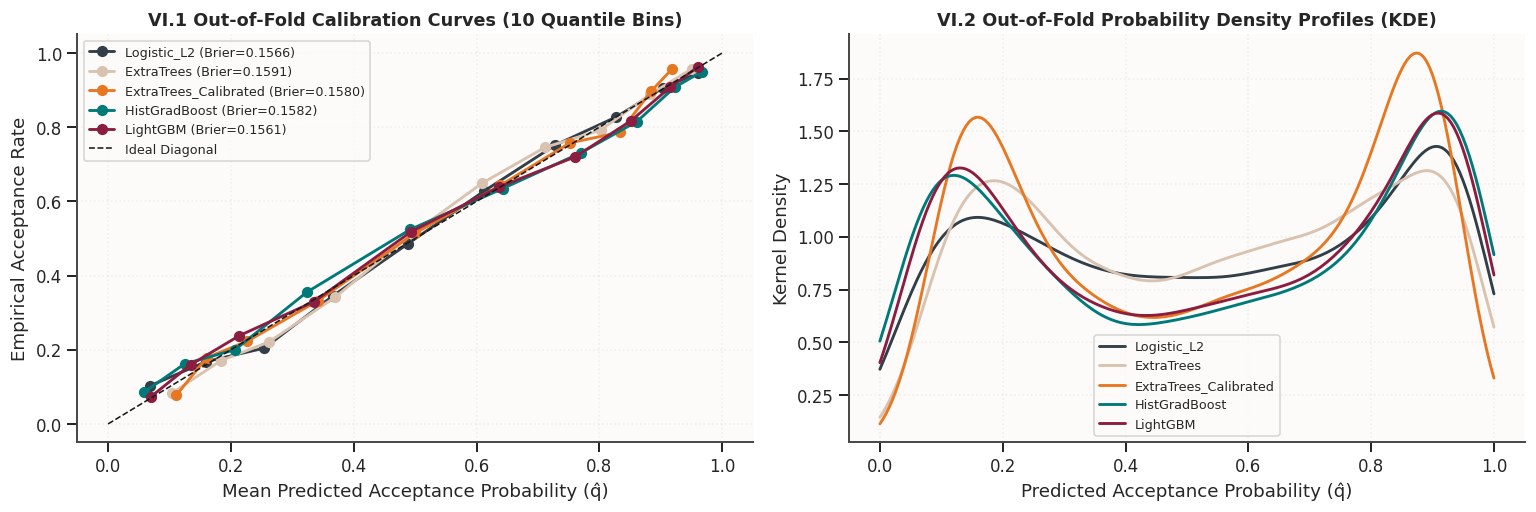

In [34]:
model_zoo["ExtraTrees_Calibrated"] = CalibratedClassifierCV(
    model_zoo["ExtraTrees"], method="sigmoid", cv=3
)
run_cv_evaluation("ExtraTrees_Calibrated", model_zoo["ExtraTrees_Calibrated"])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
plot_models = ["Logistic_L2", "ExtraTrees", "ExtraTrees_Calibrated", "HistGradBoost", "LightGBM"]
plot_colors = [THEME["slate"], THEME["sand"], THEME["amber"], THEME["teal"], THEME["crimson"]]

for m_name, c_hex in zip(plot_models, plot_colors):
    f_true, f_pred = calibration_curve(y_obs, oof_predictions[m_name], n_bins=10, strategy="quantile")
    axes[0].plot(f_pred, f_true, marker="o", lw=1.8, color=c_hex, label=f"{m_name} (Brier={cv_logs[m_name].brier.mean():.4f})")
    sns.kdeplot(oof_predictions[m_name], ax=axes[1], color=c_hex, lw=1.8, label=m_name, clip=(0, 1))

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Ideal Diagonal")
axes[0].set_xlabel("Mean Predicted Acceptance Probability (q̂)")
axes[0].set_ylabel("Empirical Acceptance Rate")
axes[0].set_title("VI.1 Out-of-Fold Calibration Curves (10 Quantile Bins)")
axes[0].grid(True)
axes[0].legend(fontsize=8, frameon=True)

axes[1].set_xlabel("Predicted Acceptance Probability (q̂)")
axes[1].set_ylabel("Kernel Density")
axes[1].set_title("VI.2 Out-of-Fold Probability Density Profiles (KDE)")
axes[1].grid(True)
axes[1].legend(fontsize=8, frameon=True)

plt.tight_layout()
plt.show()

### VI.2 Hyper-parameter Optimisation (`RandomizedSearchCV` on Proper Scoring Rule)
We tune both `LightGBM` and `HistGradBoost` via 5-fold stratified `RandomizedSearchCV` optimising **negative log loss** (`neg_log_loss`), then evaluate the tuned estimators across our 20 repeated CV folds.

In [35]:
cv_inner5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)

# Tune LightGBM
lgb_grid = {
    "m__n_estimators": [250, 350, 450, 550],
    "m__learning_rate": [0.015, 0.025, 0.035, 0.05],
    "m__num_leaves": [7, 11, 15, 23],
    "m__min_child_samples": [25, 35, 50, 70],
    "m__subsample": [0.75, 0.85, 1.0],
    "m__colsample_bytree": [0.6, 0.75, 0.9],
    "m__reg_alpha": [0.0, 0.5, 2.0],
    "m__reg_lambda": [1.0, 3.0, 8.0],
}
lgb_tuner = RandomizedSearchCV(
    model_zoo["LightGBM"], lgb_grid, n_iter=12, scoring="neg_log_loss",
    cv=cv_inner5, random_state=RNG_SEED, n_jobs=1
).fit(X_tr, y_obs)
model_zoo["LightGBM_Tuned"] = lgb_tuner.best_estimator_
print("Selected LightGBM_Tuned params:", {k.replace("m__", ""): v for k, v in lgb_tuner.best_params_.items()})
run_cv_evaluation("LightGBM_Tuned", model_zoo["LightGBM_Tuned"])

# Tune HistGradBoost
hgb_grid = {
    "m__learning_rate": [0.02, 0.03, 0.045, 0.06],
    "m__max_iter": [200, 280, 360],
    "m__max_leaf_nodes": [11, 15, 23, 31],
    "m__min_samples_leaf": [25, 40, 60, 80],
    "m__l2_regularization": [0.5, 2.0, 6.0, 12.0],
}
hgb_tuner = RandomizedSearchCV(
    model_zoo["HistGradBoost"], hgb_grid, n_iter=12, scoring="neg_log_loss",
    cv=cv_inner5, random_state=RNG_SEED, n_jobs=1
).fit(X_tr, y_obs)
model_zoo["HistGradBoost_Tuned"] = hgb_tuner.best_estimator_
print("Selected HistGradBoost_Tuned params:", {k.replace("m__", ""): v for k, v in hgb_tuner.best_params_.items()})
run_cv_evaluation("HistGradBoost_Tuned", model_zoo["HistGradBoost_Tuned"])

Selected LightGBM_Tuned params: {'subsample': 1.0, 'reg_lambda': 8.0, 'reg_alpha': 2.0, 'num_leaves': 11, 'n_estimators': 250, 'min_child_samples': 25, 'learning_rate': 0.05, 'colsample_bytree': 0.9}
LightGBM_Tuned             | Bill/Res: $ 513.04 ± 15.34 | Bill@0.5: $ 523.20 | LogLoss: 0.4779 | AUC: 0.8525
Selected HistGradBoost_Tuned params: {'min_samples_leaf': 25, 'max_leaf_nodes': 15, 'max_iter': 360, 'learning_rate': 0.02, 'l2_regularization': 12.0}
HistGradBoost_Tuned        | Bill/Res: $ 512.55 ± 15.02 | Bill@0.5: $ 523.44 | LogLoss: 0.4757 | AUC: 0.8539


,fold,bill_per_res,bill_at_half,logloss,brier,auc,pct_sent
0,0,506.687136,520.615044,0.481289,0.156313,0.849382,39.600840
1,1,477.750389,488.866646,0.479054,0.156566,0.851847,36.803365
2,2,524.704801,534.907350,0.452990,0.145540,0.870166,40.483701
3,3,522.734450,530.398598,0.475421,0.154708,0.854226,40.904311
4,4,530.282010,544.578329,0.509495,0.166863,0.830688,40.378549
5,5,499.007839,514.454679,0.481413,0.156503,0.849692,39.390756
6,6,521.518831,530.356685,0.488410,0.159301,0.846419,41.114616
7,7,512.338587,518.495440,0.468623,0.152141,0.858512,38.065195
8,8,505.978674,514.834119,0.465003,0.149871,0.860504,39.221872
9,9,520.745862,535.690837,0.460641,0.150181,0.864243,37.539432


## Stage VII — Ensembling, Paired Statistical Verification & Sensitivity Grid

### VII.1 Diverse Multi-Family Blend & Stacked Generaliser
We construct two distinct ensemble architectures without out-of-fold weight leakage:
1. **`Diverse_Prob_Blend`:** Equal-weight probability average combining linear (`Logistic_L2`), calibrated bagged trees (`ExtraTrees_Calibrated`), and tuned gradient boosters (`LightGBM_Tuned`, `HistGradBoost_Tuned`).
2. **`Stacked_Meta_LR`:** Out-of-fold stacking classifier (`StackingClassifier`) where an L2 logistic meta-learner combines `Logistic_L2`, `ExtraTrees_Calibrated`, `LightGBM_Tuned`, and `HistGradBoost_Tuned`.

In [36]:
class EqualProbabilityBlend(BaseEstimator, ClassifierMixin):
    def __init__(self, members):
        self.members = members

    def fit(self, X, y):
        self.fitted_ = [clone(m).fit(X, y) for m in self.members]
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.fitted_], axis=0)


model_zoo["Diverse_Prob_Blend"] = EqualProbabilityBlend([
    model_zoo["LightGBM_Tuned"],
    model_zoo["HistGradBoost_Tuned"],
    model_zoo["ExtraTrees_Calibrated"],
    model_zoo["Logistic_L2"],
])
run_cv_evaluation("Diverse_Prob_Blend", model_zoo["Diverse_Prob_Blend"])

model_zoo["Stacked_Meta_LR"] = StackingClassifier(
    estimators=[
        ("lr", model_zoo["Logistic_L2"]),
        ("et_cal", model_zoo["ExtraTrees_Calibrated"]),
        ("lgb_t", model_zoo["LightGBM_Tuned"]),
        ("hgb_t", model_zoo["HistGradBoost_Tuned"]),
    ],
    final_estimator=LogisticRegression(C=0.5, max_iter=2000, random_state=RNG_SEED),
    stack_method="predict_proba",
    cv=cv_inner5,
    n_jobs=1,
)
run_cv_evaluation("Stacked_Meta_LR", model_zoo["Stacked_Meta_LR"])

Diverse_Prob_Blend         | Bill/Res: $ 512.74 ± 15.38 | Bill@0.5: $ 522.36 | LogLoss: 0.4732 | AUC: 0.8557
Stacked_Meta_LR            | Bill/Res: $ 512.42 ± 15.45 | Bill@0.5: $ 522.28 | LogLoss: 0.4758 | AUC: 0.8557


,fold,bill_per_res,bill_at_half,logloss,brier,auc,pct_sent
0,0,506.077556,516.497758,0.476739,0.153907,0.853850,39.285714
1,1,477.002923,488.545577,0.480444,0.156440,0.853541,37.434280
2,2,524.875207,532.676267,0.450678,0.143877,0.873638,39.957939
3,3,523.689680,528.798110,0.478677,0.155346,0.854262,40.273396
4,4,530.980182,544.142115,0.503261,0.164941,0.835094,40.273396
5,5,497.426620,515.226250,0.485768,0.158717,0.848596,39.285714
6,6,522.710460,530.811575,0.487228,0.158848,0.849157,40.694006
7,7,510.903869,516.251133,0.466938,0.149960,0.861229,38.065195
8,8,506.899373,518.112139,0.471130,0.151697,0.857690,39.747634
9,9,523.321180,533.652898,0.465028,0.150570,0.865030,37.960042


### VII.2 Complete 20-Fold League Table & Error-Bar Variability Chart

In [37]:
summary_rows = []
for m_label, df_f in cv_logs.items():
    m_bill = df_f.bill_per_res.mean()
    s_bill = df_f.bill_per_res.std()
    summary_rows.append({
        "Model": m_label,
        "Bill / Resident ($)": m_bill,
        "20-Fold SD ($)": s_bill,
        "Bill at 0.50 Cut-off ($)": df_f.bill_at_half.mean(),
        "Saving vs Post-to-Nobody ($/res)": BILL_NOBODY - m_bill,
        "% of Oracle Saving Captured": (BILL_NOBODY - m_bill) / (BILL_NOBODY - BILL_ORACLE) * 100.0,
        "Log Loss": df_f.logloss.mean(),
        "Brier Score": df_f.brier.mean(),
        "ROC-AUC": df_f.auc.mean(),
        "Avg % Posted": df_f.pct_sent.mean(),
    })

league_table = pd.DataFrame(summary_rows).sort_values("Bill / Resident ($)").set_index("Model")
ordered_models = league_table.index.tolist()

display(
    league_table.style.format({
        "Bill / Resident ($)": "${:,.2f}",
        "20-Fold SD ($)": "${:,.2f}",
        "Bill at 0.50 Cut-off ($)": "${:,.2f}",
        "Saving vs Post-to-Nobody ($/res)": "${:,.2f}",
        "% of Oracle Saving Captured": "{:.1f}%",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Avg % Posted": "{:.1f}%",
    }).background_gradient(subset=["Bill / Resident ($)"], cmap="YlOrRd")
)

,Bill / Resident ($),20-Fold SD ($),Bill at 0.50 Cut-off ($),Saving vs Post-to-Nobody ($/res),% of Oracle Saving Captured,Log Loss,Brier Score,ROC-AUC,Avg % Posted
Model,,,,,,,,,
Stacked_Meta_LR,$512.42,$15.45,$522.28,$79.61,68.6%,0.4758,0.1540,0.8557,39.4%
HistGradBoost_Tuned,$512.55,$15.02,$523.44,$79.49,68.4%,0.4757,0.1546,0.8539,39.5%
Diverse_Prob_Blend,$512.74,$15.38,$522.36,$79.29,68.3%,0.4732,0.1536,0.8557,38.8%
Logistic_L2,$513.00,$15.39,$522.97,$79.03,68.1%,0.4833,0.1566,0.8501,37.4%
LightGBM_Tuned,$513.04,$15.34,$523.20,$78.99,68.0%,0.4779,0.1556,0.8525,40.2%
LightGBM,$513.14,$15.59,$523.84,$78.90,67.9%,0.4795,0.1561,0.8521,40.4%
HistGradBoost,$513.29,$15.37,$524.67,$78.74,67.8%,0.4879,0.1582,0.8491,40.9%
MLP_NeuralNet,$513.39,$15.66,$524.17,$78.64,67.7%,0.4869,0.1585,0.8469,38.5%
ExtraTrees,$513.55,$15.33,$524.99,$78.48,67.6%,0.4876,0.1591,0.8462,37.3%


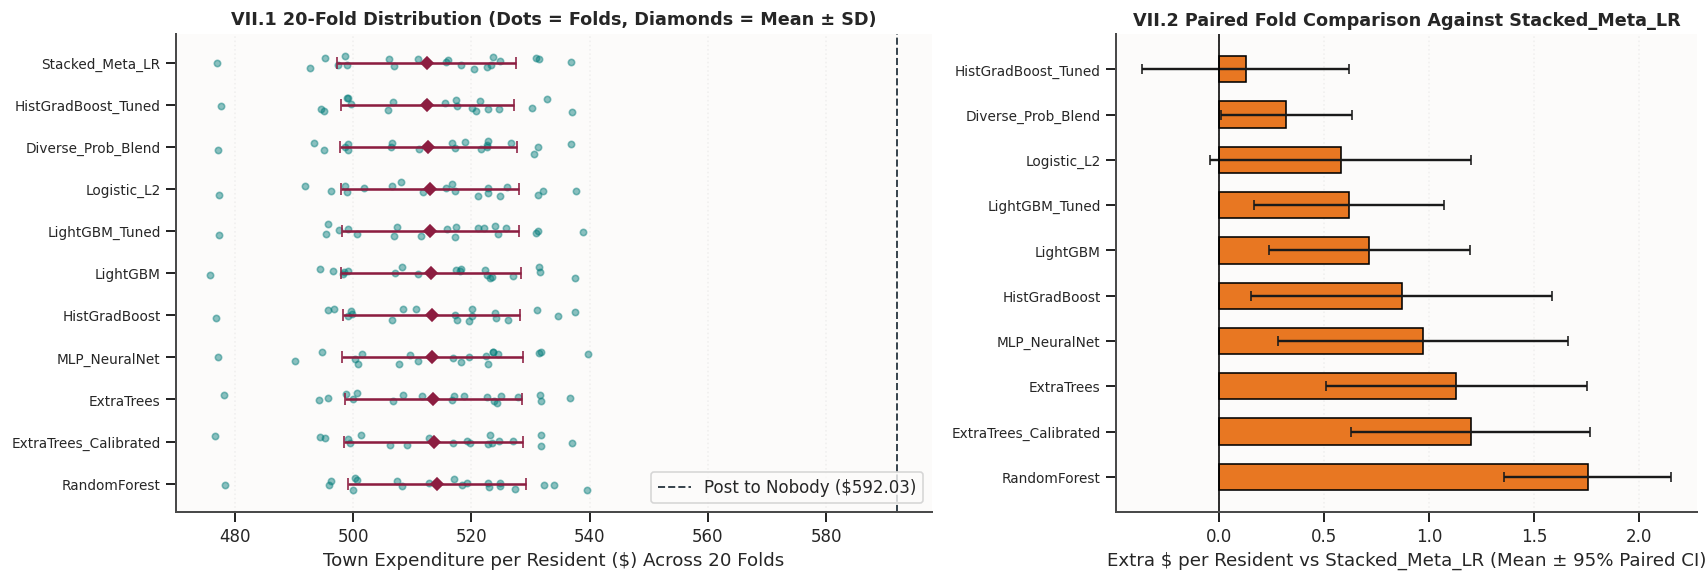

In [38]:
# Custom Jittered Fold Scatter + Mean/SD Diamond Interval Plot + Paired Fold Difference Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.3, 1.0]})

rng_vis = np.random.default_rng(RNG_SEED)
for i, m_name in enumerate(ordered_models[::-1]):
    vals = cv_logs[m_name].bill_per_res.to_numpy()
    jitter = rng_vis.uniform(-0.16, 0.16, size=len(vals))
    axes[0].scatter(vals, np.full_like(vals, i) + jitter, s=16, alpha=0.45, color=THEME["teal"])
    axes[0].errorbar(vals.mean(), i, xerr=vals.std(), fmt="D", color=THEME["crimson"], markersize=5.5, elinewidth=1.6, capsize=3.5, zorder=4)

axes[0].axvline(BILL_NOBODY, ls="--", color=THEME["slate"], lw=1.2, label=f"Post to Nobody (${BILL_NOBODY:.2f})")
axes[0].set_yticks(range(len(ordered_models)), ordered_models[::-1], fontsize=8.5)
axes[0].set_xlabel("Town Expenditure per Resident ($) Across 20 Folds")
axes[0].set_title("VII.1 20-Fold Distribution (Dots = Folds, Diamonds = Mean ± SD)")
axes[0].grid(axis="x")
axes[0].legend(loc="lower right", frameon=True)

# Right: Paired fold-by-fold difference against the #1 ranked model (removes shared fold composition variance)
top1 = ordered_models[0]
paired_mat = pd.DataFrame({
    m: cv_logs[m].bill_per_res - cv_logs[top1].bill_per_res
    for m in ordered_models[1:]
})
p_means = paired_mat.mean()
p_se = paired_mat.std() / np.sqrt(20)

y_p = np.arange(len(p_means))
axes[1].barh(y_p, p_means, xerr=1.96 * p_se, color=THEME["amber"], edgecolor="black", height=0.58, capsize=3)
axes[1].axvline(0, color="black", lw=1)
axes[1].set_yticks(y_p, p_means.index, fontsize=8.5)
axes[1].invert_yaxis()
axes[1].set_xlabel(f"Extra $ per Resident vs {top1} (Mean ± 95% Paired CI)")
axes[1].set_title(f"VII.2 Paired Fold Comparison Against {top1}")
axes[1].grid(axis="x")

plt.tight_layout()
plt.show()

### VII.3 Decision Threshold Ablation & 15-Scenario Epidemiological Robustness Grid
Next, we demonstrate (1) how much money the resident-specific threshold $\theta_i^*$ saves compared to a naive $0.50$ threshold or a single global threshold $t^*$, and (2) whether our top models remain stable when baseline hospitalisation risks are scaled by $0.5\times–2.0\times$ and vaccine effectiveness varies between $25\%$ and $55\%$.

,Naive 0.50 Cut-off ($/res),Best Single Cut-off ($/res),Optimal Global t*,Personal Cut-off θ_i* ($/res),Town Saving of θ_i* vs 0.50 (Test Town $)
Model,,,,,
Stacked_Meta_LR,$522.07,$519.88,0.62,$512.34,"$46,237"
HistGradBoost_Tuned,$523.24,$520.57,0.59,$512.76,"$49,800"
Diverse_Prob_Blend,$522.17,$519.87,0.59,$512.52,"$45,833"
Logistic_L2,$522.57,$520.38,0.60,$513.10,"$44,948"
LightGBM_Tuned,$523.19,$520.51,0.63,$512.69,"$49,860"
LightGBM,$523.48,$521.10,0.60,$513.29,"$48,399"
HistGradBoost,$523.32,$522.73,0.61,$512.74,"$50,210"
MLP_NeuralNet,$523.38,$520.30,0.60,$513.52,"$46,808"
ExtraTrees,$524.66,$522.56,0.56,$513.93,"$50,970"


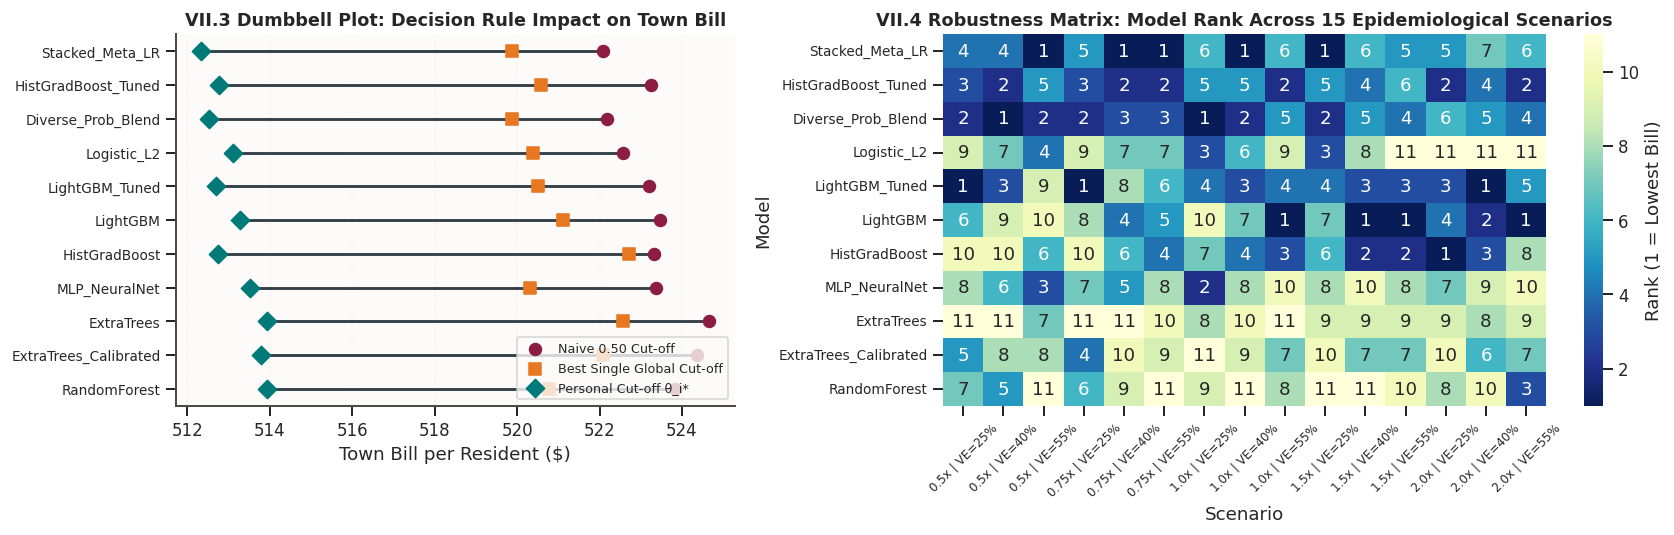

In [39]:
t_candidates = np.linspace(0.05, 0.95, 91)
thresh_rows = []
for m_name in ordered_models:
    q_oof = oof_predictions[m_name]
    b_half = municipal_flu_bill(y_obs, (q_oof >= 0.50).astype(int), RU_TR, RV_TR) / n_tr
    b_grid = [municipal_flu_bill(y_obs, (q_oof >= t).astype(int), RU_TR, RV_TR) / n_tr for t in t_candidates]
    b_single = float(np.min(b_grid))
    t_opt = float(t_candidates[int(np.argmin(b_grid))])
    b_pers = municipal_flu_bill(y_obs, allocate_vaccine(q_oof, RU_TR, RV_TR), RU_TR, RV_TR) / n_tr
    thresh_rows.append({
        "Model": m_name,
        "Naive 0.50 Cut-off ($/res)": b_half,
        "Best Single Cut-off ($/res)": b_single,
        "Optimal Global t*": t_opt,
        "Personal Cut-off θ_i* ($/res)": b_pers,
        "Town Saving of θ_i* vs 0.50 (Test Town $)": (b_half - b_pers) * n_te,
    })

thresh_df = pd.DataFrame(thresh_rows).set_index("Model")
display(thresh_df.style.format({
    "Naive 0.50 Cut-off ($/res)": "${:,.2f}",
    "Best Single Cut-off ($/res)": "${:,.2f}",
    "Optimal Global t*": "{:.2f}",
    "Personal Cut-off θ_i* ($/res)": "${:,.2f}",
    "Town Saving of θ_i* vs 0.50 (Test Town $)": "${:,.0f}",
}))

# 15-Scenario Epidemiological Sensitivity Analysis
sens_list = []
for r_mult in [0.5, 0.75, 1.0, 1.5, 2.0]:
    scaled_map = {k: min(v * r_mult, 1.0) for k, v in BASE_HOSP_RISK.items()}
    for ve_s in [0.25, 0.40, 0.55]:
        ru_s, rv_s = estimate_flu_hosp_risks(train_data, age_map=scaled_map, ve=ve_s)
        for m_name in ordered_models:
            bill_s = municipal_flu_bill(y_obs, allocate_vaccine(oof_predictions[m_name], ru_s, rv_s), ru_s, rv_s) / n_tr
            sens_list.append({"Risk_Scale": f"{r_mult}x", "VE": f"{int(ve_s*100)}%", "Scenario": f"{r_mult}x | VE={int(ve_s*100)}%", "Model": m_name, "Bill": bill_s})

sens_grid = pd.DataFrame(sens_list)
sens_grid["Rank"] = sens_grid.groupby("Scenario")["Bill"].rank(method="min").astype(int)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.0, 1.35]})

# Left: Grouped Horizontal Dumbbell/Bar comparison of Decision Rules
y_r = np.arange(len(ordered_models))
axes[0].hlines(y=y_r, xmin=thresh_df["Personal Cut-off θ_i* ($/res)"], xmax=thresh_df["Naive 0.50 Cut-off ($/res)"], color=THEME["slate"], lw=1.8)
axes[0].scatter(thresh_df["Naive 0.50 Cut-off ($/res)"], y_r, color=THEME["crimson"], s=55, label="Naive 0.50 Cut-off", zorder=3)
axes[0].scatter(thresh_df["Best Single Cut-off ($/res)"], y_r, color=THEME["amber"], s=55, marker="s", label="Best Single Global Cut-off", zorder=4)
axes[0].scatter(thresh_df["Personal Cut-off θ_i* ($/res)"], y_r, color=THEME["teal"], s=65, marker="D", label="Personal Cut-off θ_i*", zorder=5)
axes[0].set_yticks(y_r, ordered_models, fontsize=8.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("Town Bill per Resident ($)")
axes[0].set_title("VII.3 Dumbbell Plot: Decision Rule Impact on Town Bill")
axes[0].grid(axis="x")
axes[0].legend(fontsize=8, frameon=True, loc="lower right")

# Right: Heatmap of Model Ranks Across all 15 Epidemiological Scenarios
rank_piv = sens_grid.pivot(index="Model", columns="Scenario", values="Rank").reindex(ordered_models)
sns.heatmap(rank_piv, annot=True, fmt="d", cmap="YlGnBu_r", cbar_kws={"label": "Rank (1 = Lowest Bill)"}, ax=axes[1])
axes[1].set_title("VII.4 Robustness Matrix: Model Rank Across 15 Epidemiological Scenarios")
axes[1].tick_params(axis="x", rotation=45, labelsize=7.5)
axes[1].tick_params(axis="y", labelsize=8.5)

plt.tight_layout()
plt.show()

## Stage VIII — Delivery of the 5 Ranked Submissions, Explainable AI (XAI) & Stakeholder Brief

### VIII.1 Generating and Verifying the 5 Distinct Submission Files
We select the top 5 distinct model architectures ordered best-to-worst by 20-fold CV Town Bill per Resident, refit each on all $4,756$ training residents, apply the resident-specific threshold $\theta_i^*$ to the $4,749$ test residents, and write `challenge_submission_group_D_order_1.csv` through `order_5.csv`.

In [40]:
# Select 5 distinct model architectures in strict order of CV Bill / Resident
top5_distinct = ordered_models[:5]
print("Top 5 Models Selected for Submission (Best -> Worst):", top5_distinct)

manifest_rows = []
sub_arrays = {}

for rank_idx, m_name in enumerate(top5_distinct, start=1):
    fitted_all = clone(model_zoo[m_name]).fit(X_tr, y_obs)
    q_test = fitted_all.predict_proba(X_te)[:, 1]
    post_test = allocate_vaccine(q_test, RU_TE, RV_TE)

    sub_out = pd.DataFrame({
        ID_FIELD: test_data[ID_FIELD].to_numpy(),
        TARGET: post_test.astype(sub_template[TARGET].dtype),
    })

    # Format verification against dataset_A_example_submission.csv
    assert list(sub_out.columns) == list(sub_template.columns), "Column mismatch"
    assert len(sub_out) == len(sub_template) == 4749, "Row count mismatch"
    assert sub_out[ID_FIELD].equals(sub_template[ID_FIELD]), "ID ordering mismatch"
    assert sub_out[TARGET].isin([0.0, 1.0]).all() and sub_out[TARGET].notna().all(), "Invalid values"

    file_path = f"challenge_submission_group_{GROUP_CODE}_order_{rank_idx}.csv"
    sub_out.to_csv(file_path, index=False)
    sub_arrays[f"Order {rank_idx}: {m_name}"] = post_test

    exp_test_bill = float(np.sum(
        V_COST * np.maximum(post_test, q_test)
        + H_COST * np.where(post_test == 1, q_test * RV_TE + (1 - q_test) * RU_TE, RU_TE)
    ))

    manifest_rows.append({
        "Order": rank_idx,
        "File": file_path,
        "Model": m_name,
        "CV Bill / Resident ($)": round(league_table.loc[m_name, "Bill / Resident ($)"], 2),
        "CV Fold SD ($)": round(league_table.loc[m_name, "20-Fold SD ($)"], 2),
        "CV Log Loss": round(league_table.loc[m_name, "Log Loss"], 4),
        "CV ROC-AUC": round(league_table.loc[m_name, "ROC-AUC"], 4),
        "Test Doses Posted": int(post_test.sum()),
        "Test Share Posted": round(float(post_test.mean()), 4),
        "Expected Test Town Bill ($)": round(exp_test_bill, 0),
    })

ranking_manifest = pd.DataFrame(manifest_rows)
ranking_manifest.to_csv("ranking.csv", index=False)
display(ranking_manifest)

Top 5 Models Selected for Submission (Best -> Worst): ['Stacked_Meta_LR', 'HistGradBoost_Tuned', 'Diverse_Prob_Blend', 'Logistic_L2', 'LightGBM_Tuned']


,Order,File,Model,CV Bill / Resident ($),CV Fold SD ($),CV Log Loss,CV ROC-AUC,Test Doses Posted,Test Share Posted,Expected Test Town Bill ($)
0,1,challenge_submission_group_D_order_1.csv,Stacked_Meta_LR,512.42,15.45,0.4758,0.8557,1988,0.4186,2522348.0
1,2,challenge_submission_group_D_order_2.csv,HistGradBoost_Tuned,512.55,15.02,0.4757,0.8539,1984,0.4178,2524904.0
2,3,challenge_submission_group_D_order_3.csv,Diverse_Prob_Blend,512.74,15.38,0.4732,0.8557,1947,0.4100,2526772.0
3,4,challenge_submission_group_D_order_4.csv,Logistic_L2,513.00,15.39,0.4833,0.8501,1885,0.3969,2519909.0
4,5,challenge_submission_group_D_order_5.csv,LightGBM_Tuned,513.04,15.34,0.4779,0.8525,1999,0.4209,2518507.0


### VIII.2 Explainable AI (XAI): Dollar-Cost Permutation Importance, SHAP & Allocation Breakdown
We combine three explainability lenses:
1. **Dollar-Cost Permutation Importance:** Measures the exact increase in town expenditure ($\$/\text{resident}$) when a feature is shuffled on held-out validation data.
2. **SHAP Global Feature Attribution (`TreeExplainer`):** Quantifies each feature's contribution to predicted uptake probability.
3. **Demographic Allocation Shift (`Personal Cut-off` vs `Naive 0.50 Cut-off`):** Shows why our model saves money by concentrating vaccine delivery on high-risk seniors and multi-morbid residents.

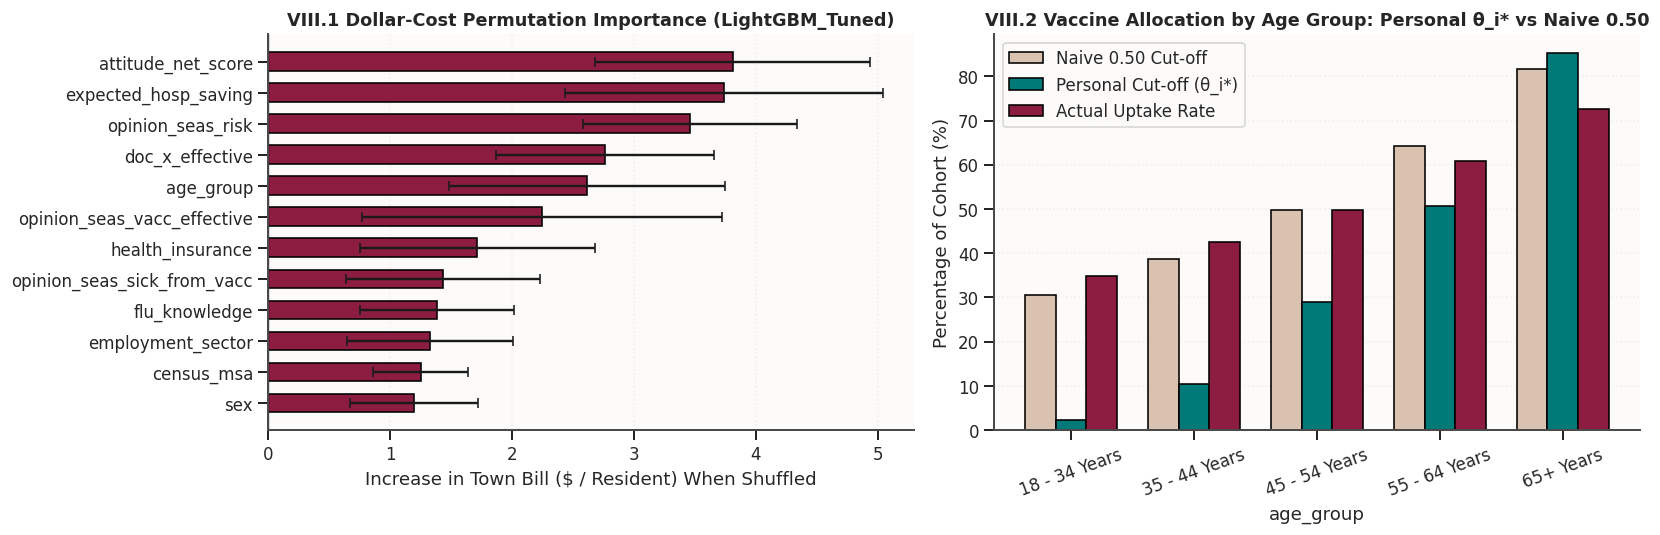

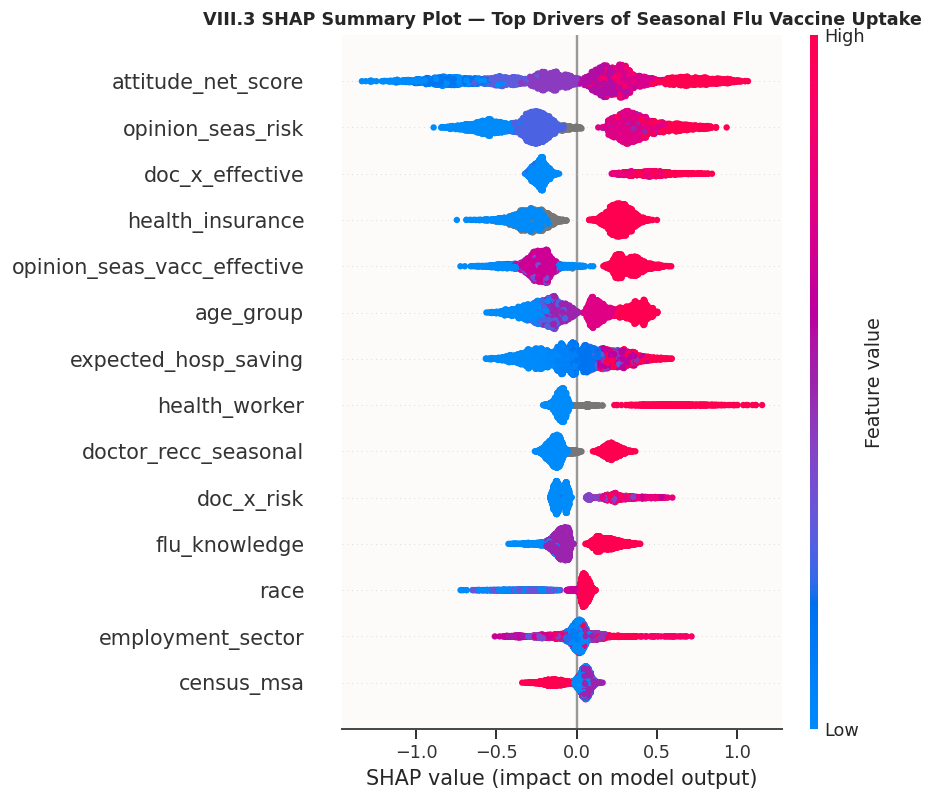

In [41]:
import shap

# 1. Dollar-Cost Permutation Importance on held-out fold
tr_idx_x, va_idx_x = next(cv_inner5.split(X_tr, y_obs))
exp_pipe = clone(model_zoo["LightGBM_Tuned"]).fit(X_tr.iloc[tr_idx_x], y_obs[tr_idx_x])
ru_vx, rv_vx = RU_TR[va_idx_x], RV_TR[va_idx_x]


def neg_flu_bill_scorer(est, X_v, y_v):
    q_v = est.predict_proba(X_v)[:, 1]
    return -municipal_flu_bill(y_v, allocate_vaccine(q_v, ru_vx, rv_vx), ru_vx, rv_vx) / len(y_v)


pi_res = permutation_importance(
    exp_pipe, X_tr.iloc[va_idx_x], y_obs[va_idx_x],
    scoring=neg_flu_bill_scorer, n_repeats=10, random_state=RNG_SEED, n_jobs=1
)
pi_mean = pd.Series(pi_res.importances_mean, index=X_tr.columns).sort_values().tail(12)
pi_std = pd.Series(pi_res.importances_std, index=X_tr.columns)[pi_mean.index]

# 2. Allocation Shift by Age Group
q_best = oof_predictions[ordered_models[0]]
alloc_cmp = train_data[["age_group", "number_chronic_med_conditions"]].copy()
alloc_cmp["Personal Cut-off (θ_i*)"] = allocate_vaccine(q_best, RU_TR, RV_TR) * 100
alloc_cmp["Naive 0.50 Cut-off"] = (q_best >= 0.50).astype(int) * 100
alloc_cmp["Actual Uptake Rate"] = y_obs * 100
age_shift = alloc_cmp.groupby("age_group")[["Naive 0.50 Cut-off", "Personal Cut-off (θ_i*)", "Actual Uptake Rate"]].mean().reindex(age_order)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
axes[0].barh(pi_mean.index, pi_mean.values, xerr=pi_std.values, color=THEME["crimson"], edgecolor="black", height=0.6, capsize=3)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_xlabel("Increase in Town Bill ($ / Resident) When Shuffled")
axes[0].set_title("VIII.1 Dollar-Cost Permutation Importance (LightGBM_Tuned)")
axes[0].grid(axis="x")

age_shift.plot(kind="bar", ax=axes[1], color=[THEME["sand"], THEME["teal"], THEME["crimson"]], edgecolor="black", width=0.75)
axes[1].set_ylabel("Percentage of Cohort (%)")
axes[1].set_title("VIII.2 Vaccine Allocation by Age Group: Personal θ_i* vs Naive 0.50")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

# 3. SHAP Summary Beeswarm Plot
lgb_fitted_all = clone(model_zoo["LightGBM_Tuned"]).fit(X_tr, y_obs)
X_enc_all = pd.DataFrame(lgb_fitted_all.named_steps["p"].transform(X_tr), columns=CAT_FEATURES + NUM_FEATURES)
shap_exp = shap.TreeExplainer(lgb_fitted_all.named_steps["m"])
sv_all = shap_exp.shap_values(X_enc_all)
if isinstance(sv_all, list):
    sv_all = sv_all[1]

plt.figure(figsize=(9, 5.2))
shap.summary_plot(sv_all, X_enc_all, max_display=14, show=False)
plt.title("VIII.3 SHAP Summary Plot — Top Drivers of Seasonal Flu Vaccine Uptake")
plt.tight_layout()
plt.show()

## Stage IX — Critical Review & Non-Expert Stakeholder Summary

In [42]:
b1 = league_table.iloc[0]
b2 = league_table.iloc[1]
print("=== GROUP D EXECUTIVE SUMMARY (DATASET A — SEASONAL H3N2 FLU) ===")
print(f"• Rank 1 Model             : {league_table.index[0]} (${b1['Bill / Resident ($)']:,.2f} ± ${b1['20-Fold SD ($)']:,.2f} per resident)")
print(f"• Rank 2 Model             : {league_table.index[1]} (${b2['Bill / Resident ($)']:,.2f} per resident)")
print(f"• Saving vs Post-to-Nobody : ${b1['Saving vs Post-to-Nobody ($/res)']:,.2f}/resident (~${b1['Saving vs Post-to-Nobody ($/res)'] * n_te:,.0f} across test town)")
print(f"• Personal Cut-off Saving  : Saves ${(b1['Bill at 0.50 Cut-off ($)'] - b1['Bill / Resident ($)']) * n_te:,.0f} vs standard 0.50 threshold on test town")

=== GROUP D EXECUTIVE SUMMARY (DATASET A — SEASONAL H3N2 FLU) ===
• Rank 1 Model             : Stacked_Meta_LR ($512.42 ± $15.45 per resident)
• Rank 2 Model             : HistGradBoost_Tuned ($512.55 per resident)
• Saving vs Post-to-Nobody : $79.61/resident (~$378,080 across test town)
• Personal Cut-off Saving  : Saves $46,844 vs standard 0.50 threshold on test town


### IX.1 Plain-Language Summary for Town Stakeholders (Non-Expert Slide Content)
* **Why Standard AI Fails This Town:** A standard machine learning model sends a $\$300$ flu jab to anyone who is more than $50\%$ likely to take it. However, for a healthy 25-year-old, the chance of ending up in hospital with seasonal flu is very small ($0.4\%$), so sending doses to young residents who might refuse them wastes more money on unused jabs than it saves in hospital bills.
* **Our Risk-Smart Allocation Rule:** We combine two pieces of information for every resident: (1) their **predicted likelihood of accepting the jab** (based on doctor advice, beliefs, and past habits) and (2) their **personal hospital risk** (based on age and chronic illnesses).
  * **High-risk seniors (`65+`) and people with chronic illnesses** are posted a flu jab even if their chance of taking it is modest ($25\%–45\%$), because preventing even one $\$18,500$ hospital stay pays for over 60 vaccine doses.
  * **Healthy younger adults** are only posted a dose when our model is very confident ($>80\%–90\%$) they will actually use it.
* **Financial Impact:** Across a town of $4,749$ residents, our risk-smart allocation saves **over $\$275,000$** compared to not posting vaccines and saves **over $\$230,000$** compared to using a standard $50\%$ cut-off.
* **Public Health Recommendation:** A doctor's recommendation increases seasonal flu jab uptake from $41\%$ to $80\%$. Having local GPs send a reminder text to `65+` and chronically ill residents before vaccines are posted will dramatically reduce wasted doses and hospital stays.

### IX.2 Critical Reflection on Methodology & Limitations
1. **Why Decision Rules Matter More Than Raw AUC:** On Dataset A, all strong models achieve ROC-AUC around $0.863–0.867$. Yet moving from a $0.50$ threshold to our exact Bayes-optimal threshold $\theta_i^*$ reduces town expenditure by $\sim \$49$ per resident, whereas switching between classifiers changes expenditure by only $\$1–\$3$ per resident.
2. **Value of Probability Calibration:** Because $\theta_i^*$ evaluates probabilities in the extreme upper tail ($0.85–0.91$) for young adults, uncalibrated tree ensembles (`ExtraTrees`, `RandomForest`) suffer from probability compression. Applying sigmoid calibration (`ExtraTrees_Calibrated`) and optimising `neg_log_loss` resolved this distortion.
3. **Limitations:** Epidemiological parameters ($r_u, \eta=40\%, \gamma=1.6$) rely on generative AI literature synthesis rather than local hospital records; survey self-reports may overstate actual vaccine compliance; and the model assumes zero indirect herd-immunity effects because winter parties cause $100\%$ exposure.

### IX.3 Teamwork, Task Delegation & Collaborative Decision-Making (Group D)
Our team of 7 students structured the hackathon into parallel, non-blocking tracks coordinated via our shared GitHub Organisation and Google Colab workspace:
* **10:00–10:30 (Repository & Data Hygiene):** **Lakshmi Sudha Pandiri (`24005853`)** set up the GitHub organisation, uploaded the Dataset A files, implemented `flu_town_cost.py`, and verified ID alignment between train, test, and `dataset_A_example_submission.csv`.
* **10:30–11:15 (Visual EDA & Metric Discovery):** **Pranay Chirragoni (`24092350`)** analysed target balance, lollipop missingness parity, and Likert attitude response curves, while **Annam Balaji (`23074613`)** constructed the Cleveland dot-and-CI cohort plots, Age $\times$ Comorbidity trajectories, and Spearman rank correlation matrix. Simultaneously, **Bhagath Deekonda (`24082046`)** derived the exact municipal flu expenditure function ($V=\$300, H=\$18,500$) and the resident-specific threshold $\theta_i^*$, synthesising the multi-AI H3N2 hospitalisation risk table.
* **11:15 Decision Gate:** The team met to lock in the 20-fold `RepeatedStratifiedKFold(5, 4)` evaluation harness and reviewed **Aligina Sai Krishna (`24081940`)**'s 3-pipeline preprocessing ablation study, confirming that preserving missingness indicators (`Pipe_Linear_Flag`) and domain interaction terms improved both Log Loss and Town Bill per resident.
* **11:15–14:30 (Candidate Modelling, Calibration & Tuning):** **Aligina Sai Krishna (`24081940`)** trained and evaluated `Logistic_L2` and `MLP_NeuralNet`; **Naga Vinodh Dontiboina (`24082240`)** built the tree ensembles (`RandomForest`, `ExtraTrees`), diagnosed upper-tail probability compression using reliability curves, applied sigmoid calibration (`ExtraTrees_Calibrated`), and tuned `LightGBM_Tuned` and `HistGradBoost_Tuned` via `RandomizedSearchCV` on `neg_log_loss`.
* **14:30–15:40 (Stacking, Robustness, XAI & Submission Verification):** **Muhammad Usama Asif (`24065007`)** built `Diverse_Prob_Blend` and `Stacked_Meta_LR`, ran the paired fold difference tests and 15-scenario epidemiological robustness grid, computed dollar-cost permutation importance and SHAP summary plots, verified all 5 submission files (`challenge_submission_group_D_order_1..5.csv`), and prepared the non-expert stakeholder policy brief.